# Task 4 – Szenarien für die Prüfung

Was passiert im Netz am Ende von Teil 4 (Windpark an Bus 1, PV-Freiflächenanlage an Bus 12, Wohngebiet mit PV-Haushalten und Heimspeichern, rONT-Regelung, S1–S3 offen), wenn sich Wetter, Verbrauch oder Netz ändern? Jedes Szenario besteht aus

- **Frage** und **Annahme** (was genau verändert wird),
- **Rechnung** gegen einen Referenzlauf mit unverändertem Netz in derselben typischen Woche,
- **Kennzahlentabelle** und **Zeitverlauf**,
- **Befund** mit physikalischer Erklärung.

Für Änderungen am Wetter oder am Verbrauch gibt es ein neues Werkzeug: **Profile kopieren und bearbeiten** (`profilaenderung.py`, Abschnitt 1). Damit lässt sich die Leistung einzelner Elemente einmalig oder periodisch auf einen festen Wert setzen, mit einem Faktor skalieren oder um einen Betrag erhöhen.

Voraussetzung: Die Notebooks Teil 1 bis 4a wurden ausgeführt (Simulation `w4_kombi_W1_P12`). Gerechnet wird jeweils nur die typische Woche, um die es geht (168 Lastflüsse je Variante); alle Varianten heißen `w4_p_…` und überschreiben keine Simulation aus Teil 1 bis 8.

| Nr. | Szenario | Woche |
|---|---|---|
| 3 | Mittags ziehen Wolken auf | Juli |
| 4 | Die Haushalte verbrauchen mehr als üblich | Januar |
| 5 | Dunkelflaute: 100 / 60 / 30 / 0 % der normalen Einspeisung | Januar |
| 6 | Starkwind nachts bei Schwachlast, größerer Windpark | Juni |
| 7 | Sturmabschaltung des Windparks bei Volllast | Januar |
| 8 | Sonniger Sonntag mit niedriger Last, heute und Zukunft | Juli |
| 9 | S1 wird bei viel Wind geschlossen | Dezember |
| 10 | Ausfall von Line 2-3 mit Wiederversorgung | Januar |
| 11 | Ausfall von Trafo 0-1 | Januar |
| 12 | Der Stufenschalter fällt aus | Januar, Juli |
| 13 | Windpark mit cos φ = 0,95 untererregt | Januar |
| 14 | Spannung im 110-kV-Netz 1,00 bzw. 1,05 pu | Januar, Juli |
| 15 | Zusätzliche Einspeisung an Bus 8 (Line 3-8) | Juli |
| 16 | Heimspeicher: ohne, normal, doppelt so groß | Juli |
| 17 | Übersicht |  |

## Importe

In [5]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import simulation as sim
import profilaenderung as pa
import pruefung as pr
from pruefung import WIND, PV_ALLE, PV_HAUSHALTE, HAUSHALTE
from elements import Generator, Profile

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

sim.ONLY_RUN_IF_CHANGED = True

## 1 Werkzeug: Profile kopieren und bearbeiten

Jedes Element (Last oder Erzeuger) bekommt seine Leistung aus einem Profil, z. B. alle PV-Anlagen aus dem PV-Profil. Eine **Profiländerung** bearbeitet eine Kopie dieses Profils nur für die ausgewählten Elemente; alle anderen Elemente behalten das Original.

```python
pa.immer(elemente, faktor=… | wert_mw=… | plus_mw=…, monate=None)
pa.einmal(elemente, …, datum="2025-07-23", von=11, bis=14)          # oder monat="JULY", wochentag=2
pa.periodisch(elemente, …, alle_h=24, start_h=17, dauer_h=5)        # jeden Tag 17–22 Uhr
```

| Parameter | Bedeutung |
|---|---|
| `elemente` | regulärer Ausdruck auf den Elementnamen, z. B. `"^Windpark$"`, `"^LV PV"` (alle PV-Haushalte), `"^LV Load R"` (Haushalte im Wohngebiet) |
| `faktor` | Leistung × Faktor (0,3 = 30 % der normalen Leistung) |
| `wert_mw` | Leistung fest auf diesen Wert in MW (je Element) |
| `plus_mw` | Leistung + Betrag in MW (je Element) |
| `einmal` | ein Tag, Stunden `von` bis `bis` (ohne Tag: ganze Woche des Monats) |
| `periodisch` | alle `alle_h` Stunden für `dauer_h` Stunden, ab Stunde `start_h` der Woche (Montag 0 Uhr = 0): täglich = 24, wöchentlich = 168 |

Die Änderungen werden mit `s.changeSetting("profile_edits", [...])` an eine Simulation gehängt (in `pr.szenario` über `aenderungen=`). Sie gehören zum Fingerabdruck: Gespeicherte Ergebnisse werden nur wiederverwendet, wenn die Änderungen gleich sind. Die Blindleistung folgt über den cos φ, die Heimspeicher rechnen ihren Fahrplan mit der geänderten Leistung.

Kurznamen für die Elemente in diesem Notebook:

In [6]:
pd.DataFrame({"Muster": [WIND, PV_ALLE, PV_HAUSHALTE, HAUSHALTE],
              "Elemente": ["Windpark (30 MW, Bus 1)", "PV-Freifläche (Bus 12) und alle PV-Anlagen der Haushalte",
                           "nur PV-Anlagen der Haushalte", "Haushaltslasten im Wohngebiet (R1, R11, R15 … R18)"]},
             index=["WIND", "PV_ALLE", "PV_HAUSHALTE", "HAUSHALTE"])

,Muster,Elemente
WIND,^Windpark$,"Windpark (30 MW, Bus 1)"
PV_ALLE,^PV-Freifläche$|^LV PV,PV-Freifläche (Bus 12) und alle PV-Anlagen der Haushalte
PV_HAUSHALTE,^LV PV,nur PV-Anlagen der Haushalte
HAUSHALTE,^LV Load R,"Haushaltslasten im Wohngebiet (R1, R11, R15 … R18)"


Daten der typischen Wochen (für `einmal(datum=…)`):

In [7]:
pa.typische_wochen()

,Mo,Di,Mi,Do,Fr,Sa,So
Januar,2025-01-06,2025-01-07,2025-01-08,2025-01-09,2025-01-10,2025-01-11,2025-01-12
Februar,2025-02-03,2025-02-04,2025-02-05,2025-02-06,2025-02-07,2025-02-08,2025-02-09
März,2025-03-03,2025-03-04,2025-03-05,2025-03-06,2025-03-07,2025-03-08,2025-03-09
April,2025-04-07,2025-04-08,2025-04-09,2025-04-10,2025-04-11,2025-04-12,2025-04-13
Mai,2025-05-19,2025-05-20,2025-05-21,2025-05-22,2025-05-23,2025-05-24,2025-05-25
Juni,2025-06-09,2025-06-10,2025-06-11,2025-06-12,2025-06-13,2025-06-14,2025-06-15
Juli,2025-07-21,2025-07-22,2025-07-23,2025-07-24,2025-07-25,2025-07-26,2025-07-27
August,2025-08-04,2025-08-05,2025-08-06,2025-08-07,2025-08-08,2025-08-09,2025-08-10
September,2025-09-08,2025-09-09,2025-09-10,2025-09-11,2025-09-12,2025-09-13,2025-09-14
Oktober,2025-10-13,2025-10-14,2025-10-15,2025-10-16,2025-10-17,2025-10-18,2025-10-19


**Beispiele** (ohne Lastfluss, nur die bearbeitete Kopie des Profils):

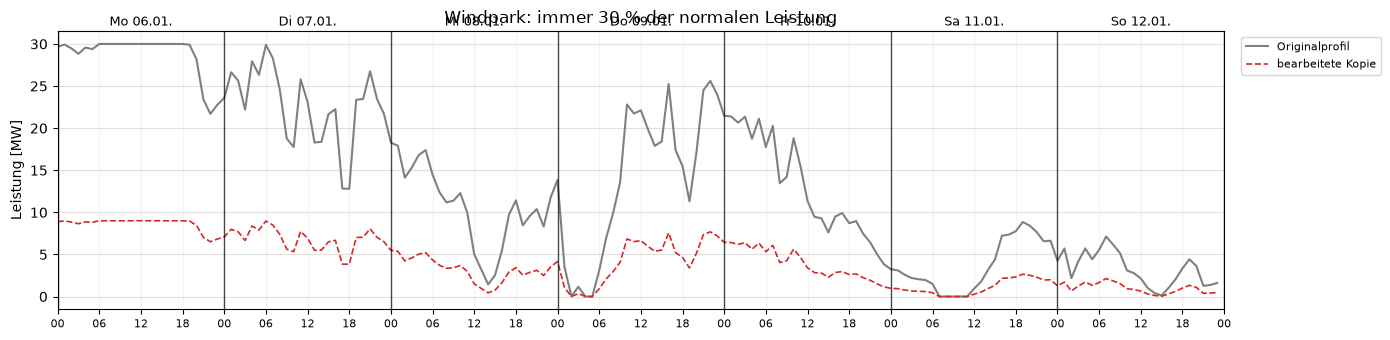

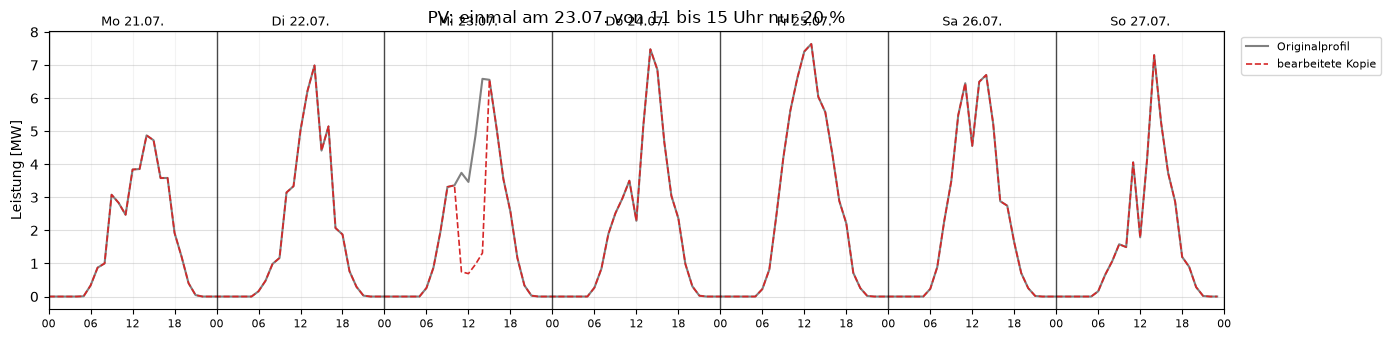

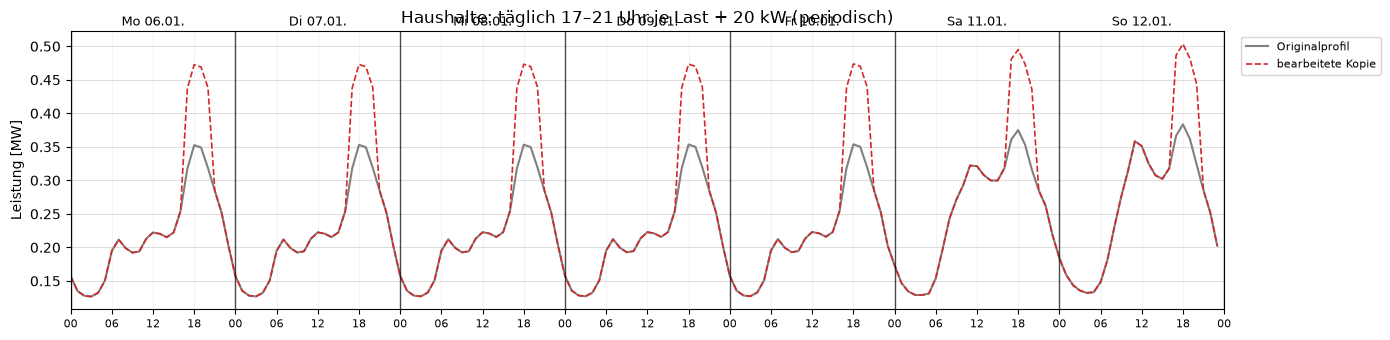

In [8]:
b = pr.basis()
beispiel = [pa.immer(WIND, faktor=0.3, name="Dunkelflaute 30 %")]
pr.profil_vorschau(b, WIND, beispiel, monat="JANUARY", titel="Windpark: immer 30 % der normalen Leistung")

beispiel = [pa.einmal(PV_ALLE, faktor=0.2, datum="2025-07-23", von=11, bis=15, name="Wolken")]
pr.profil_vorschau(b, PV_ALLE, beispiel, monat="JULY", titel="PV: einmal am 23.07. von 11 bis 15 Uhr nur 20 %")

beispiel = [pa.periodisch(HAUSHALTE, plus_mw=0.02, alle_h=24, start_h=17, dauer_h=4, name="Abendspitze")]
pr.profil_vorschau(b, HAUSHALTE, beispiel, monat="JANUARY", tabelle="load",
                   titel="Haushalte: täglich 17–21 Uhr je Last + 20 kW (periodisch)")

Kontrolle, welche Elemente ein Muster trifft:

In [9]:
pa.betroffene_elemente(b, [pa.immer(WIND, faktor=1), pa.immer(PV_ALLE, faktor=1)])

,Änderung,Tabelle,Element
0,Nr. 1,sgen,Windpark
1,Nr. 2,sgen,PV-Freifläche
2,Nr. 2,sgen,LV PV R1
3,Nr. 2,sgen,LV PV Speicher R1
4,Nr. 2,sgen,LV PV R11
5,Nr. 2,sgen,LV PV Speicher R11
6,Nr. 2,sgen,LV PV R15
7,Nr. 2,sgen,LV PV Speicher R15
8,Nr. 2,sgen,LV PV R16
9,Nr. 2,sgen,LV PV Speicher R16


## 2 Ausgangsnetz und Referenzläufe

Ausgangsnetz ist das Netz am Ende von Teil 4 (`pr.basis()`: Kombination aus Teil 4a mit PV-Haushalten, Variante „heute“). Für jede typische Woche, die in einem Szenario vorkommt, wird es einmal unverändert gerechnet; alle Varianten werden mit diesem Referenzlauf verglichen.

In [10]:
b = pr.basis()
REF = {m: pr.szenario(f"ref_{m.lower()}", b, monate=[m]) for m in ("JANUARY", "JUNE", "JULY", "DECEMBER")}
pr.kennzahlen({f"Referenz {m.title()}": s for m, s in REF.items()})

,Referenz January,Referenz June,Referenz July,Referenz December
Stunden gerechnet,168,168,168,168
davon nicht konvergiert,0,0,0,0
U min MS [pu],0.952 (Bus 11),0.977 (Bus 11),0.978 (Bus 11),0.952 (Bus 11)
U max MS [pu],1.023 (Bus 1),1.025 (Bus 1),1.025 (Bus 1),1.023 (Bus 1)
U min NS [pu],0.950 (R15),0.951 (C12),0.954 (C12),0.951 (R15)
U max NS [pu],1.026 (R1),1.048 (R15),1.049 (R15),1.027 (R15)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,0,0,0
"Stunden außerhalb 0,95 … 1,05 (NS)",0,0,0,0
"Stunden außerhalb 0,90 … 1,10 (alle)",0,0,0,0
Leitung max MS [%],78.491 (Line 2-3),53.921 (Line 2-3),53.339 (Line 2-3),76.881 (Line 2-3)


**Referenz:** In allen vier Wochen bleiben alle Busse im Planungsband 0,95 … 1,05 pu, kein Betriebsmittel ist über 100 %. Im Winter (Januar, Dezember) bestimmt die Abendspitze das Netz: U min 0,952 pu an Bus 11, Trafo 0-1 bis 88 % (bei Starkwind in Rückspeisung). Im Sommer (Juni, Juli) bestimmt die Mittagssonne das Wohngebiet: Rückspeisung über Ortsnetztrafo R in 50 Stunden, U max 1,049 pu an R15, der rONT stuft dann nach unten.

## 3 Mittags ziehen Wolken auf

**Frage:** Was passiert, wenn an einem sonnigen Sommertag mittags Wolken aufziehen?

**Annahme:** Am sonnigsten Tag der Juliwoche liefern alle PV-Anlagen (Freifläche und Haushalte) von 11 bis 15 Uhr nur 20 % (**a**). Zusätzlich ein Wolkenzug über die ganze Woche: jede zweite Stunde nur 30 % (**b**). Die Stundenauflösung bildet nur den Mittelwert jeder Stunde ab; schnelle Wolkenzüge im Minutenbereich sind feiner, als das Modell auflöst.

In [11]:
pv_tag = pr.leistung(REF["JULY"], PV_ALLE).resample("D").sum()
sonnig = pv_tag.idxmax().strftime("%Y-%m-%d")
print("sonnigster Tag der Juliwoche:", sonnig)
wolken = {"Referenz": REF["JULY"],
          "a) Wolken 11–15 Uhr (20 %)": pr.szenario("wolken_mittag", b, monate=["JULY"],
              aenderungen=[pa.einmal(PV_ALLE, faktor=0.2, datum=sonnig, von=11, bis=15, name="Wolken")]),
          "b) Wolkenzug (jede 2. Stunde 30 %)": pr.szenario("wolkenzug", b, monate=["JULY"],
              aenderungen=[pa.periodisch(PV_ALLE, faktor=0.3, alle_h=2, start_h=1, dauer_h=1, name="Wolkenzug")])}
tab = pr.kennzahlen(wolken)
tab

sonnigster Tag der Juliwoche: 2025-07-25


,Referenz,a) Wolken 11–15 Uhr (20 %),b) Wolkenzug (jede 2. Stunde 30 %)
Stunden gerechnet,168,168,168
davon nicht konvergiert,0,0,0
U min MS [pu],0.978 (Bus 11),0.978 (Bus 11),0.978 (Bus 11)
U max MS [pu],1.025 (Bus 1),1.025 (Bus 1),1.025 (Bus 1)
U min NS [pu],0.954 (C12),0.954 (C12),0.953 (C12)
U max NS [pu],1.049 (R15),1.049 (R15),1.050 (R15)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,0,0
"Stunden außerhalb 0,95 … 1,05 (NS)",0,0,0
"Stunden außerhalb 0,90 … 1,10 (alle)",0,0,0
Leitung max MS [%],53.339 (Line 2-3),53.339 (Line 2-3),53.339 (Line 2-3)


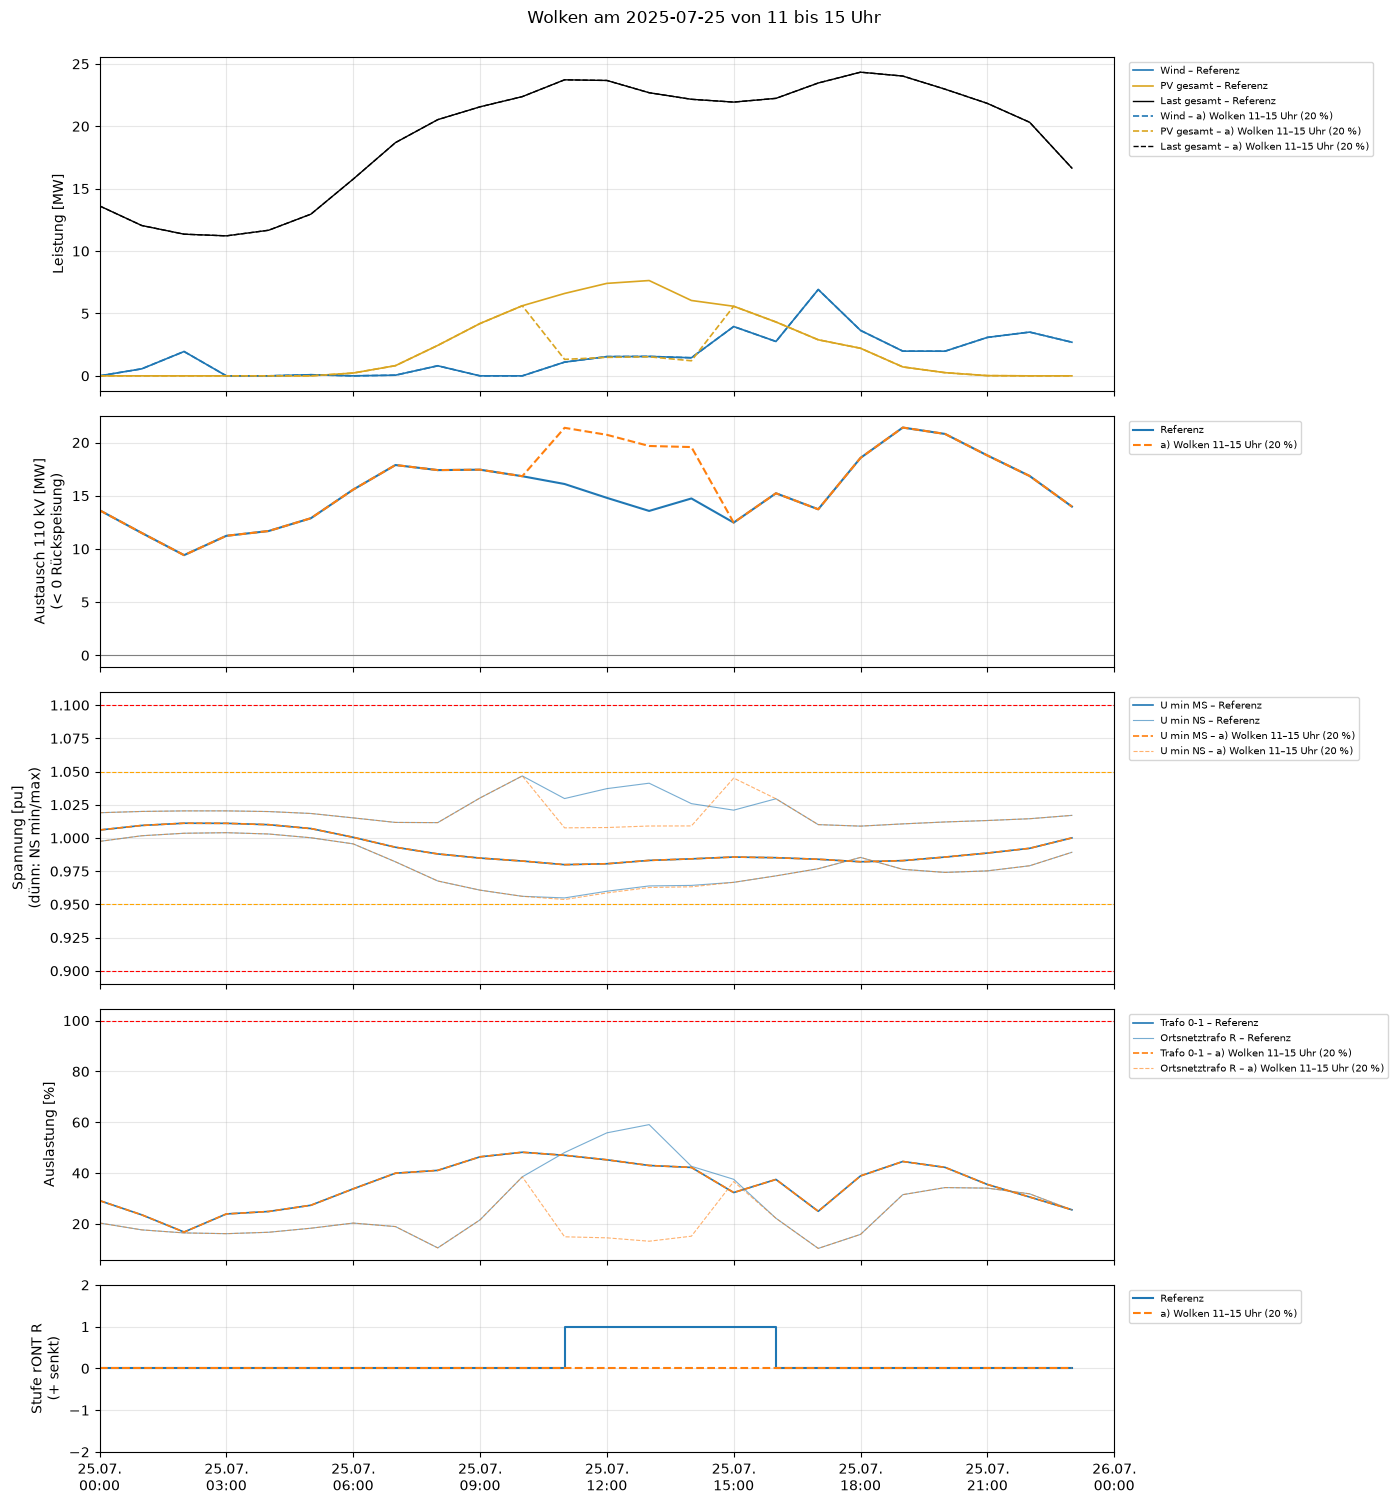

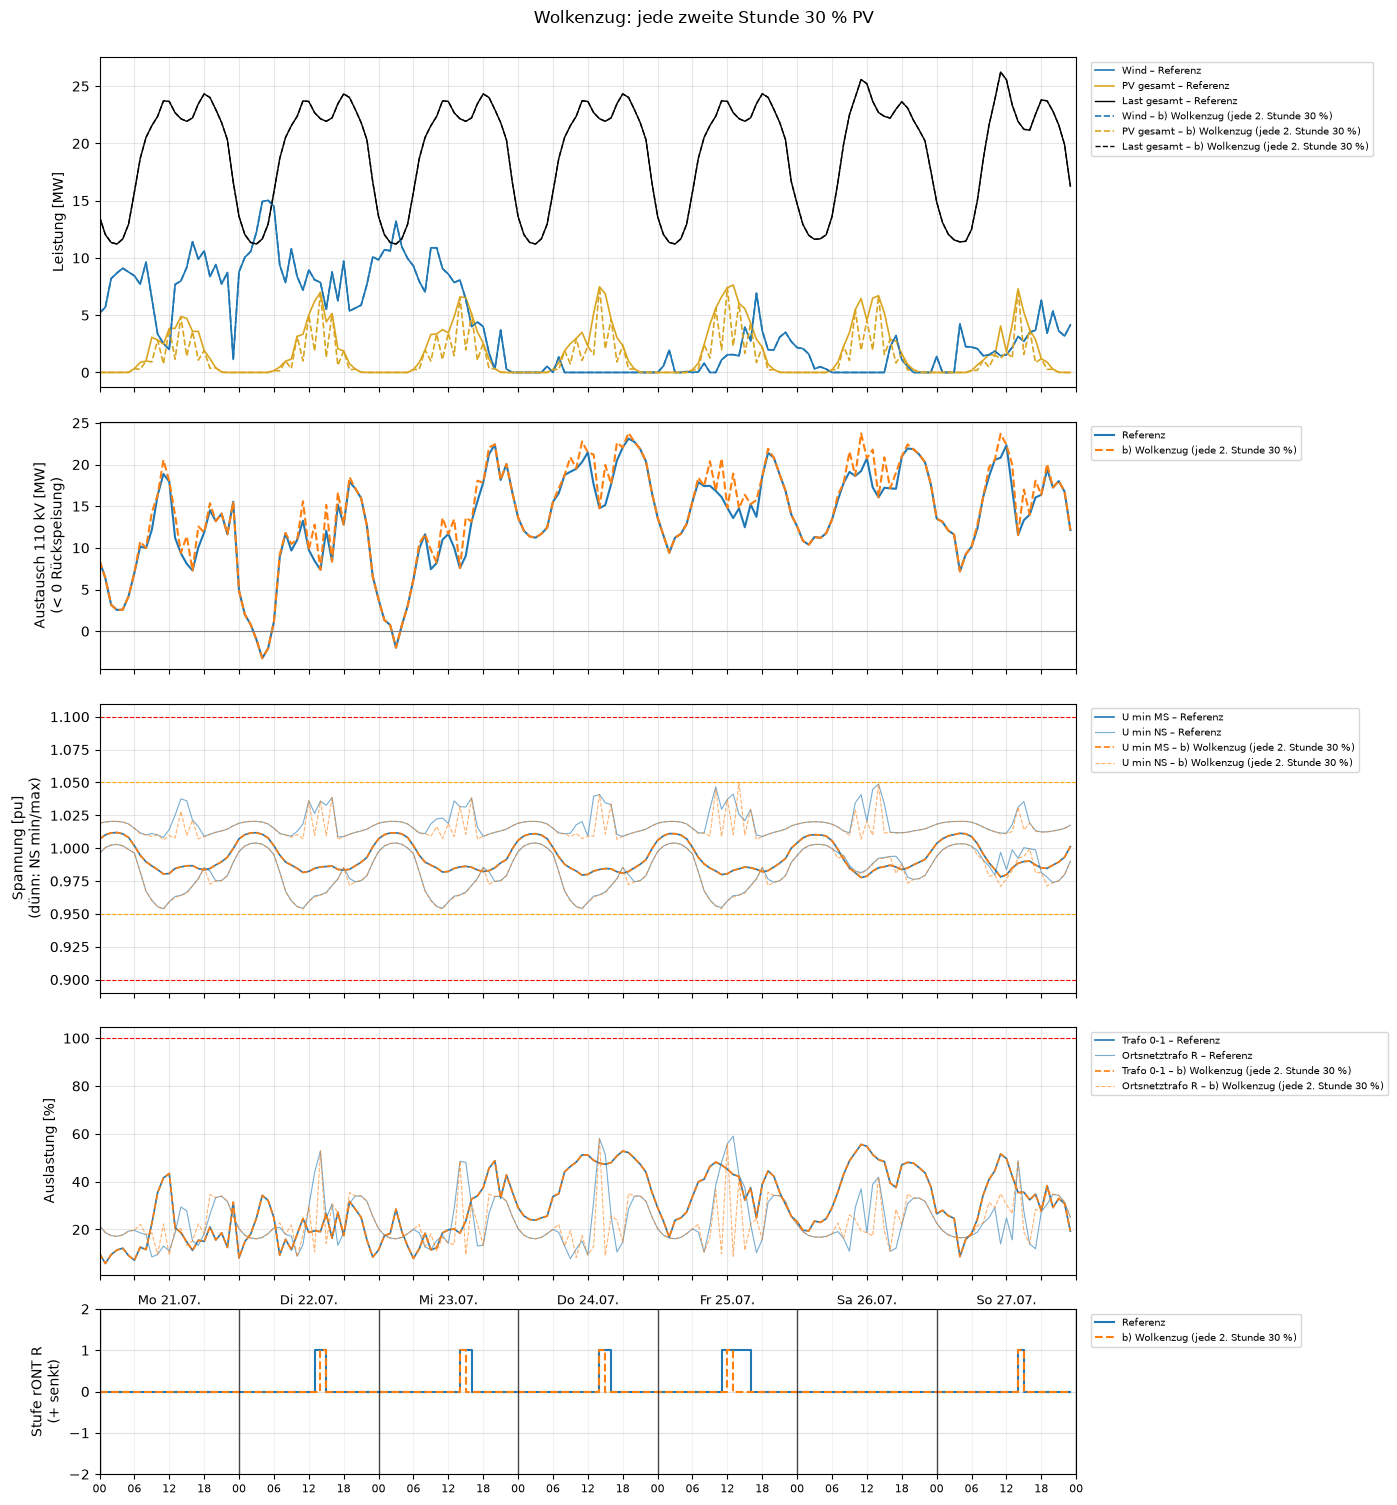

In [12]:
pr.verlauf({k: wolken[k] for k in list(wolken)[:2]}, f"Wolken am {sonnig} von 11 bis 15 Uhr", tage=[sonnig])
pr.verlauf({k: wolken[k] for k in (list(wolken)[0], list(wolken)[2])}, "Wolkenzug: jede zweite Stunde 30 % PV", monat="JULY")

In [13]:
# Wohngebiet in den Wolkenstunden: Austausch über Ortsnetztrafo R, Speicher, rONT
h = pd.date_range(f"{sonnig} 09:00", periods=9, freq="h")
zeilen = {}
for k in list(wolken)[:2]:
    r = wolken[k].results
    zeilen[k] = pd.DataFrame({"PV Haushalte [kW]": 1000 * pr.leistung(wolken[k], PV_HAUSHALTE).loc[h],
                              "Speicher [kW] (> 0 Laden)": 1000 * r.storage_p_mw.sum(axis=1).loc[h],
                              "Ortsnetztrafo R [kW] (< 0 Rückspeisung)": 1000 * r.trafo_p_mw[pr.ONT["R"]].loc[h],
                              "Stufe rONT R": r.tap_pos[pr.ONT["R"]].loc[h],
                              "U max NS [pu]": r.vm_pu[[c for c in r.vm_pu if c.startswith("LV Bus R")]].max(axis=1).loc[h]})
pd.concat(zeilen, axis=1).set_index(h.strftime("%H:%M")).round(3)

Referenz                                                                                              a) Wolken 11–15 Uhr (20 %)                            \
      PV Haushalte [kW] Speicher [kW] (> 0 Laden) Ortsnetztrafo R [kW] (< 0 Rückspeisung) Stufe rONT R U max NS [pu]          PV Haushalte [kW] Speicher [kW] (> 0 Laden)   
09:00           296.970                    16.656                                -126.297          0.0         1.030                    296.970                    16.656   
10:00           397.712                     0.000                                -238.036          0.0         1.047                    397.712                     0.000   
11:00           467.516                     0.000                                -291.162          1.0         1.030                     93.503                     0.000   
12:00           524.746                     0.000                                -339.466          1.0         1.037                    104.949                     0.000   
13:00           540.825                     0.000                                -360.437          1.0         1.041                    108.165                     0.000   
14:00           427.661                     0.000                                -257.586          1.0         1.026                     85.532                     0.000   
15:00           394.817                     0.000                                -225.072          1.0         1.021                    394.817                     0.000   
16:00           305.657                     0.000                                -127.193          0.0         1.030                    305.657                     0.000   
17:00           204.686                     0.000                                  -3.676          0.0         1.016                    204.686                     0.000   

                                                                          
      Ortsnetztrafo R [kW] (< 0 Rückspeisung) Stufe rONT R U max NS [pu]  
09:00                                -126.297          0.0         1.030  
10:00                                -238.036          0.0         1.047  
11:00                                  76.800          0.0         1.014  
12:00                                  71.923          0.0         1.015  
13:00                                  62.636          0.0         1.015  
14:00                                  79.944          0.0         1.016  
15:00                                -225.183          0.0         1.045  
16:00                                -127.193          0.0         1.030  
17:00                                  -3.676          0.0         1.016

**Befund Wolken:**

- **a) Wolken 11–15 Uhr:** Im Wohngebiet kippt der Fluss innerhalb einer Stunde von **360 kW Rückspeisung auf 63 bis 80 kW Bezug** (Sprung um gut 400 kW über Ortsnetztrafo R). Die Spannung an den Strangenden fällt von 1,04 auf 1,015 pu, der rONT stuft von +1 auf 0 zurück. Um 15 Uhr kommt die Sonne wieder: Die Spannung springt auf 1,045 pu, bevor der rONT wieder absenkt. Im MS-Netz bezieht Trafo 0-12 die fehlende PV-Leistung zusätzlich; die Spannungen ändern sich kaum, weil die PV-Freiflächenanlage an der Sammelschiene einspeist.
- **Speicher:** Sie sind um 10 Uhr schon voll und laden nicht. Sie entladen in den Wolkenstunden auch nicht, weil selbst 20 % PV noch über dem Verbrauch der Speicherhaushalte liegt. Der Wolkeneinbruch wird also nicht abgefedert; der Speicher reagiert nur auf den eigenen Haushalt.
- **b) Wolkenzug:** Rückspeisung aus dem Wohngebiet nur noch in 21 statt 50 Stunden, Trafo 0-12 und der Bezug aus dem 110-kV-Netz steigen leicht. Die Zahl der rONT-Stufenschritte bleibt gleich, weil das Modell nur Stundenwerte kennt: Wechselt die Bewölkung im Minutentakt, würde ein realer Regler ohne Verzögerung ständig schalten. Deshalb haben rONT eine Totzeit von 30 bis 60 s und zählen die Schaltspiele (Verschleiß).
- **Prüfungsantwort:** Wolken erzeugen schnelle Leistungssprünge in die Gegenrichtung. Spannungsprobleme entstehen kurzzeitig im Ortsnetz (Strangende), nicht im MS-Netz. Grenzen werden in diesem Netz nicht verletzt.

## 4 Die Haushalte verbrauchen mehr als üblich

**Frage:** Was passiert, wenn die Haushalte mehr Strom verbrauchen, z. B. in einer Kältewelle, durch Wärmepumpen oder durch E-Autos, die abends laden?

**Annahme (Januarwoche, Haushalte im Wohngebiet):**
- **a)** immer + 30 % (z. B. Kältewelle, mehr Heizlüfter und Wärmepumpen),
- **b)** täglich 17–21 Uhr + 60 % (z. B. E-Autos laden nach Feierabend),
- **c)** immer + 60 % (Belastungsgrenze des Wohngebiets).

In [14]:
haushalte = {"Referenz": REF["JANUARY"],
             "a) immer +30 %": pr.szenario("last_plus30", b, monate=["JANUARY"],
                 aenderungen=[pa.immer(HAUSHALTE, faktor=1.3, name="+30 %")]),
             "b) täglich 17–21 Uhr +60 %": pr.szenario("last_abend60", b, monate=["JANUARY"],
                 aenderungen=[pa.periodisch(HAUSHALTE, faktor=1.6, alle_h=24, start_h=17, dauer_h=4, name="Abend +60 %")]),
             "c) immer +60 %": pr.szenario("last_plus60", b, monate=["JANUARY"],
                 aenderungen=[pa.immer(HAUSHALTE, faktor=1.6, name="+60 %")])}
tab = pr.kennzahlen(haushalte)
tab

,Referenz,a) immer +30 %,b) täglich 17–21 Uhr +60 %,c) immer +60 %
Stunden gerechnet,168,168,168,168
davon nicht konvergiert,0,0,0,0
U min MS [pu],0.952 (Bus 11),0.952 (Bus 11),0.952 (Bus 11),0.952 (Bus 11)
U max MS [pu],1.023 (Bus 1),1.023 (Bus 1),1.023 (Bus 1),1.023 (Bus 1)
U min NS [pu],0.950 (R15),0.952 (R15),0.934 (R15),0.932 (R15)
U max NS [pu],1.026 (R1),1.044 (R1),1.039 (R1),1.047 (R1)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,0,0,0
"Stunden außerhalb 0,95 … 1,05 (NS)",0,0,16,16
"Stunden außerhalb 0,90 … 1,10 (alle)",0,0,0,0
Leitung max MS [%],78.491 (Line 2-3),78.491 (Line 2-3),78.491 (Line 2-3),78.491 (Line 2-3)


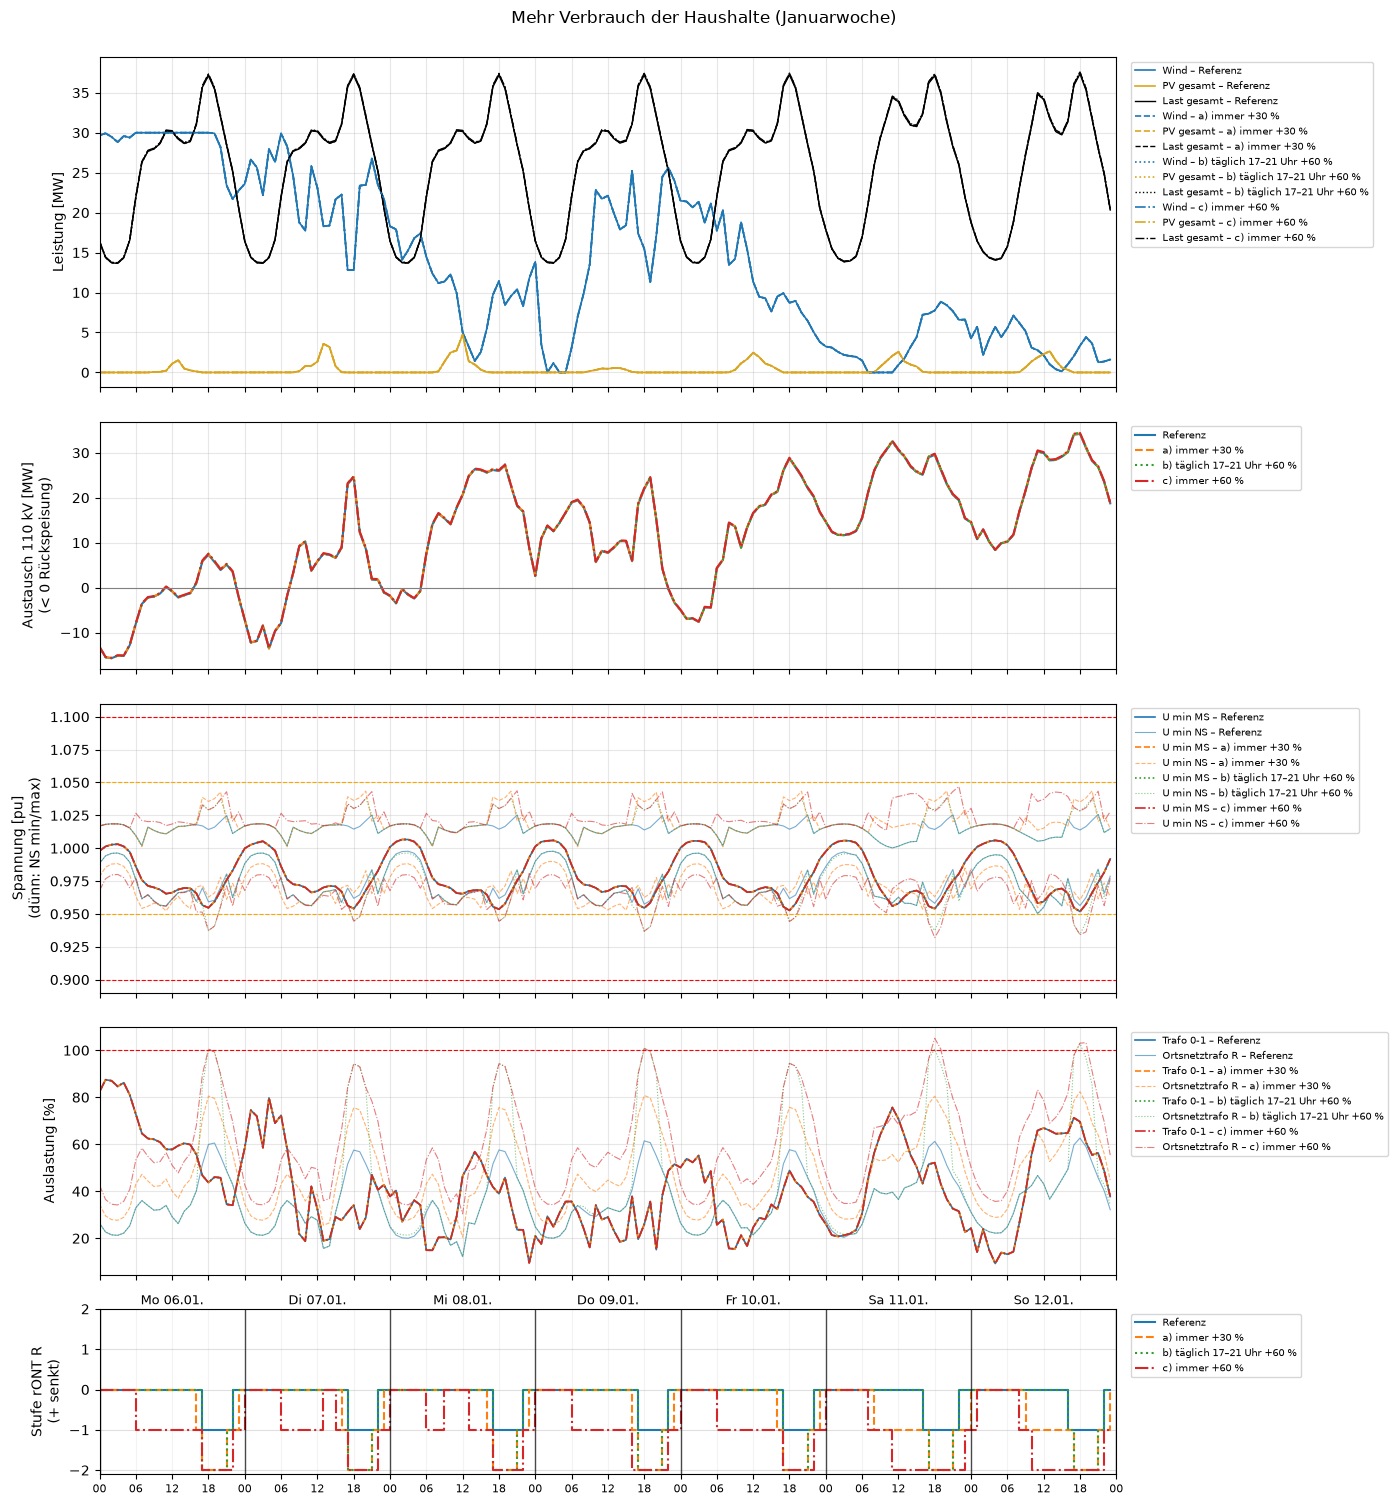

In [15]:
pr.verlauf(haushalte, "Mehr Verbrauch der Haushalte (Januarwoche)", monat="JANUARY")

**Befund mehr Verbrauch:**

- **a) +30 %:** Der rONT gleicht die Spannung aus (U min NS 0,952 pu), schaltet dafür häufiger (38 statt 24 Stufenschritte). Weil er alle Busse des Wohngebiets gleich anhebt, steigt die Sammelschiene R1 auf 1,044 pu. Ortsnetztrafo R ist mit 82 % ausgelastet, Kabel R1-R2 mit 86 %.
- **b) Abendspitze +60 % und c) immer +60 %:** Jetzt werden zuerst die **Betriebsmittel** zum Problem: Ortsnetztrafo R bis 103 bzw. 105 %, Kabel R1-R2 bis 108 bzw. 111 %, in 9 bis 10 Stunden überlastet. Zugleich fällt die Spannung an R15 auf 0,93 pu: Der rONT kann nicht weiter anheben, weil die Sammelschiene R1 sonst über 1,05 pu stiege. Der Spannungsunterschied innerhalb des Strangs ist größer als das Band; das kann ein Stufenschalter grundsätzlich nicht ausgleichen.
- **MS-Netz:** keine Änderung (U min 0,952 pu, Trafo 0-1 87,5 %). Das Wohngebiet ist für das MS-Netz klein.
- **Prüfungsantwort:** Mehr Verbrauch belastet zuerst Ortsnetztrafo und erstes Kabel thermisch; die Spannung hält der rONT, bis der Spannungsfall im Strang größer wird als die Bandbreite. Abhilfe: Lastmanagement (§ 14a EnWG, Laden zeitlich verteilen), Speicher abends entladen, größerer Trafo, Kabel verstärken.

## 5 Dunkelflaute

**Frage:** Was passiert, wenn Wind und Sonne über eine ganze Woche weniger liefern als normal?

**Annahme:** In der Januarwoche (höchste Last) liefern der Windpark und alle PV-Anlagen nur 60 %, 30 % bzw. 0 % ihrer normalen Leistung (Faktor auf beide Profile). 100 % ist der Referenzlauf.

In [16]:
FAKTOREN = [1.0, 0.6, 0.3, 0.0]
flaute = {}
for f in FAKTOREN:
    if f == 1.0:
        flaute["100 % (Referenz)"] = REF["JANUARY"]
    else:
        flaute[f"{f:.0%}"] = pr.szenario(f"flaute_{int(f * 100)}", b, monate=["JANUARY"],
                                         aenderungen=[pa.immer(WIND, faktor=f), pa.immer(PV_ALLE, faktor=f)])
tab = pr.kennzahlen(flaute)
tab

,100 % (Referenz),60%,30%,0%
Stunden gerechnet,168,168,168,168
davon nicht konvergiert,0,0,0,0
U min MS [pu],0.952 (Bus 11),0.951 (Bus 11),0.950 (Bus 11),0.949 (Bus 11)
U max MS [pu],1.023 (Bus 1),1.023 (Bus 1),1.023 (Bus 1),1.022 (Bus 12)
U min NS [pu],0.950 (R15),0.952 (R15),0.952 (R15),0.952 (R15)
U max NS [pu],1.026 (R1),1.025 (R1),1.025 (R1),1.025 (R1)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,0,0,5
"Stunden außerhalb 0,95 … 1,05 (NS)",0,0,0,0
"Stunden außerhalb 0,90 … 1,10 (alle)",0,0,0,0
Leitung max MS [%],78.491 (Line 2-3),78.547 (Line 2-3),78.592 (Line 2-3),78.638 (Line 2-3)


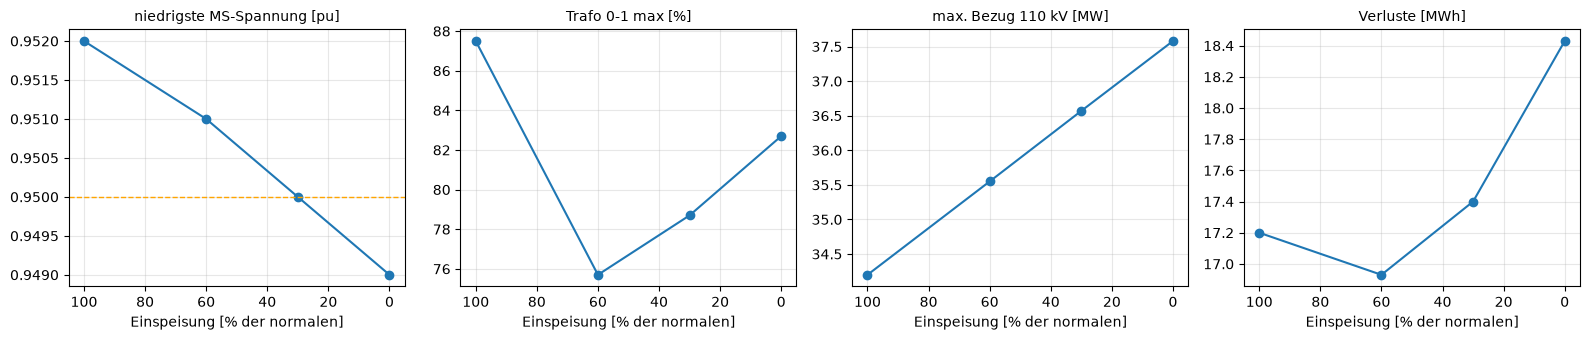

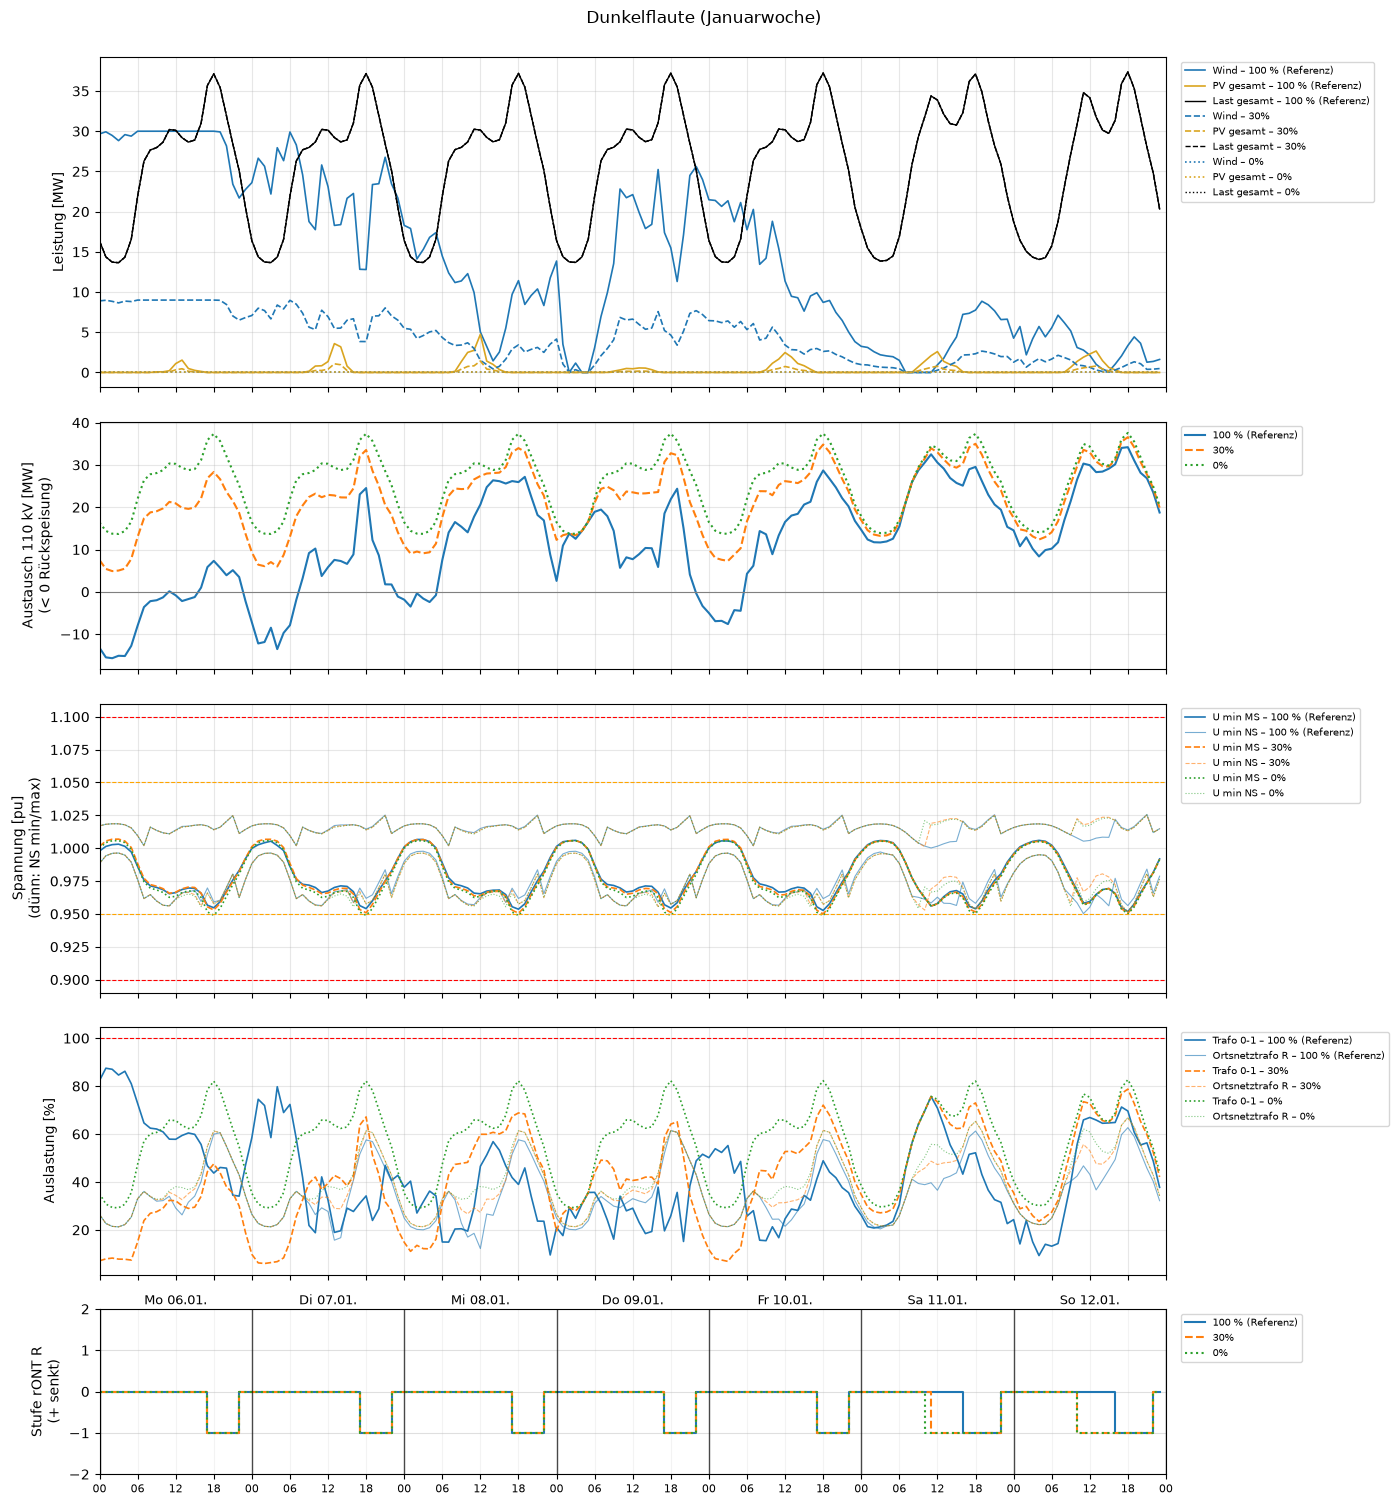

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
x = [100 * f for f in FAKTOREN]
for ax, (zeile, titel) in zip(axes, [("U min MS [pu]", "niedrigste MS-Spannung [pu]"), ("Trafo 0-1 max [%]", "Trafo 0-1 max [%]"),
                                     ("max. Bezug 110 kV [MW]", "max. Bezug 110 kV [MW]"), ("Verluste [MWh]", "Verluste [MWh]")]):
    ax.plot(x, [pr.zahl(tab, zeile, k) for k in tab.columns], "o-")
    ax.set_title(titel, fontsize=10)
    ax.set_xlabel("Einspeisung [% der normalen]")
    ax.invert_xaxis()
    ax.grid(alpha=0.3)
axes[0].axhline(0.95, color="orange", ls="--", lw=1)
plt.tight_layout()
plt.show()
pr.verlauf({k: flaute[k] for k in ("100 % (Referenz)", "30%", "0%")}, "Dunkelflaute (Januarwoche)", monat="JANUARY")

**Befund Dunkelflaute:**

- **Spannung:** Mit weniger Einspeisung sinkt die niedrigste MS-Spannung nur wenig (0,952 → 0,949 pu bei 0 %). Die Erzeuger hängen an den Sammelschienen und stützen die Spannung in den Abgängen kaum.
- **Trafo 0-1 verhält sich nicht monoton:** 87,5 % bei voller Einspeisung (Rückspeisung bei Starkwind), 75,7 % bei 60 % (Wind und Last gleichen sich besser aus), dann wieder steigend auf 82,7 % bei 0 % (Höchstlast ohne Wind). Die Auslastung hängt am Betrag des Stroms; beide Richtungen belasten.
- **Austausch:** Rückspeisung ins 110-kV-Netz verschwindet ab 30 %, der höchste Bezug steigt auf das Niveau ohne Erzeuger. Die Verluste sind bei 60 % am kleinsten und bei 0 % am größten.
- **Prüfungsantwort:** Eine Dunkelflaute bringt das Netz in den Zustand ohne Erzeuger zurück, den es ohnehin beherrschen muss (Auslegung auf Höchstlast). Kritisch wird sie für die Energieversorgung (Bezug aus dem 110-kV-Netz), nicht für das Verteilnetz. Erzeuger ersetzen keine Netzkapazität.

## 6 Starkwind nachts bei Schwachlast

**Frage:** Was passiert, wenn nachts bei geringer Last der Wind voll weht? Und wenn der Windpark größer wäre?

**Annahme (Juniwoche, geringe Last):** Der Windpark speist jede Nacht von 0 bis 6 Uhr mit voller Leistung ein: **a)** 30 MW (installierte Leistung), **b)** 45 MW (Windpark um 50 % größer, nur nachts betrachtet).

In [18]:
starkwind = {"Referenz": REF["JUNE"],
             "a) nachts 30 MW": pr.szenario("starkwind_30", b, monate=["JUNE"],
                 aenderungen=[pa.periodisch(WIND, wert_mw=30, alle_h=24, start_h=0, dauer_h=6, name="nachts volle Leistung")]),
             "b) nachts 45 MW": pr.szenario("starkwind_45", b, monate=["JUNE"],
                 aenderungen=[pa.periodisch(WIND, wert_mw=45, alle_h=24, start_h=0, dauer_h=6, name="größerer Windpark")])}
tab = pr.kennzahlen(starkwind)
tab

,Referenz,a) nachts 30 MW,b) nachts 45 MW
Stunden gerechnet,168,168,168
davon nicht konvergiert,0,0,0
U min MS [pu],0.977 (Bus 11),0.977 (Bus 11),0.977 (Bus 11)
U max MS [pu],1.025 (Bus 1),1.024 (Bus 12),1.024 (Bus 12)
U min NS [pu],0.951 (C12),0.951 (C12),0.951 (C12)
U max NS [pu],1.048 (R15),1.048 (R15),1.048 (R15)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,0,0
"Stunden außerhalb 0,95 … 1,05 (NS)",0,0,0
"Stunden außerhalb 0,90 … 1,10 (alle)",0,0,0
Leitung max MS [%],53.921 (Line 2-3),53.921 (Line 2-3),53.921 (Line 2-3)


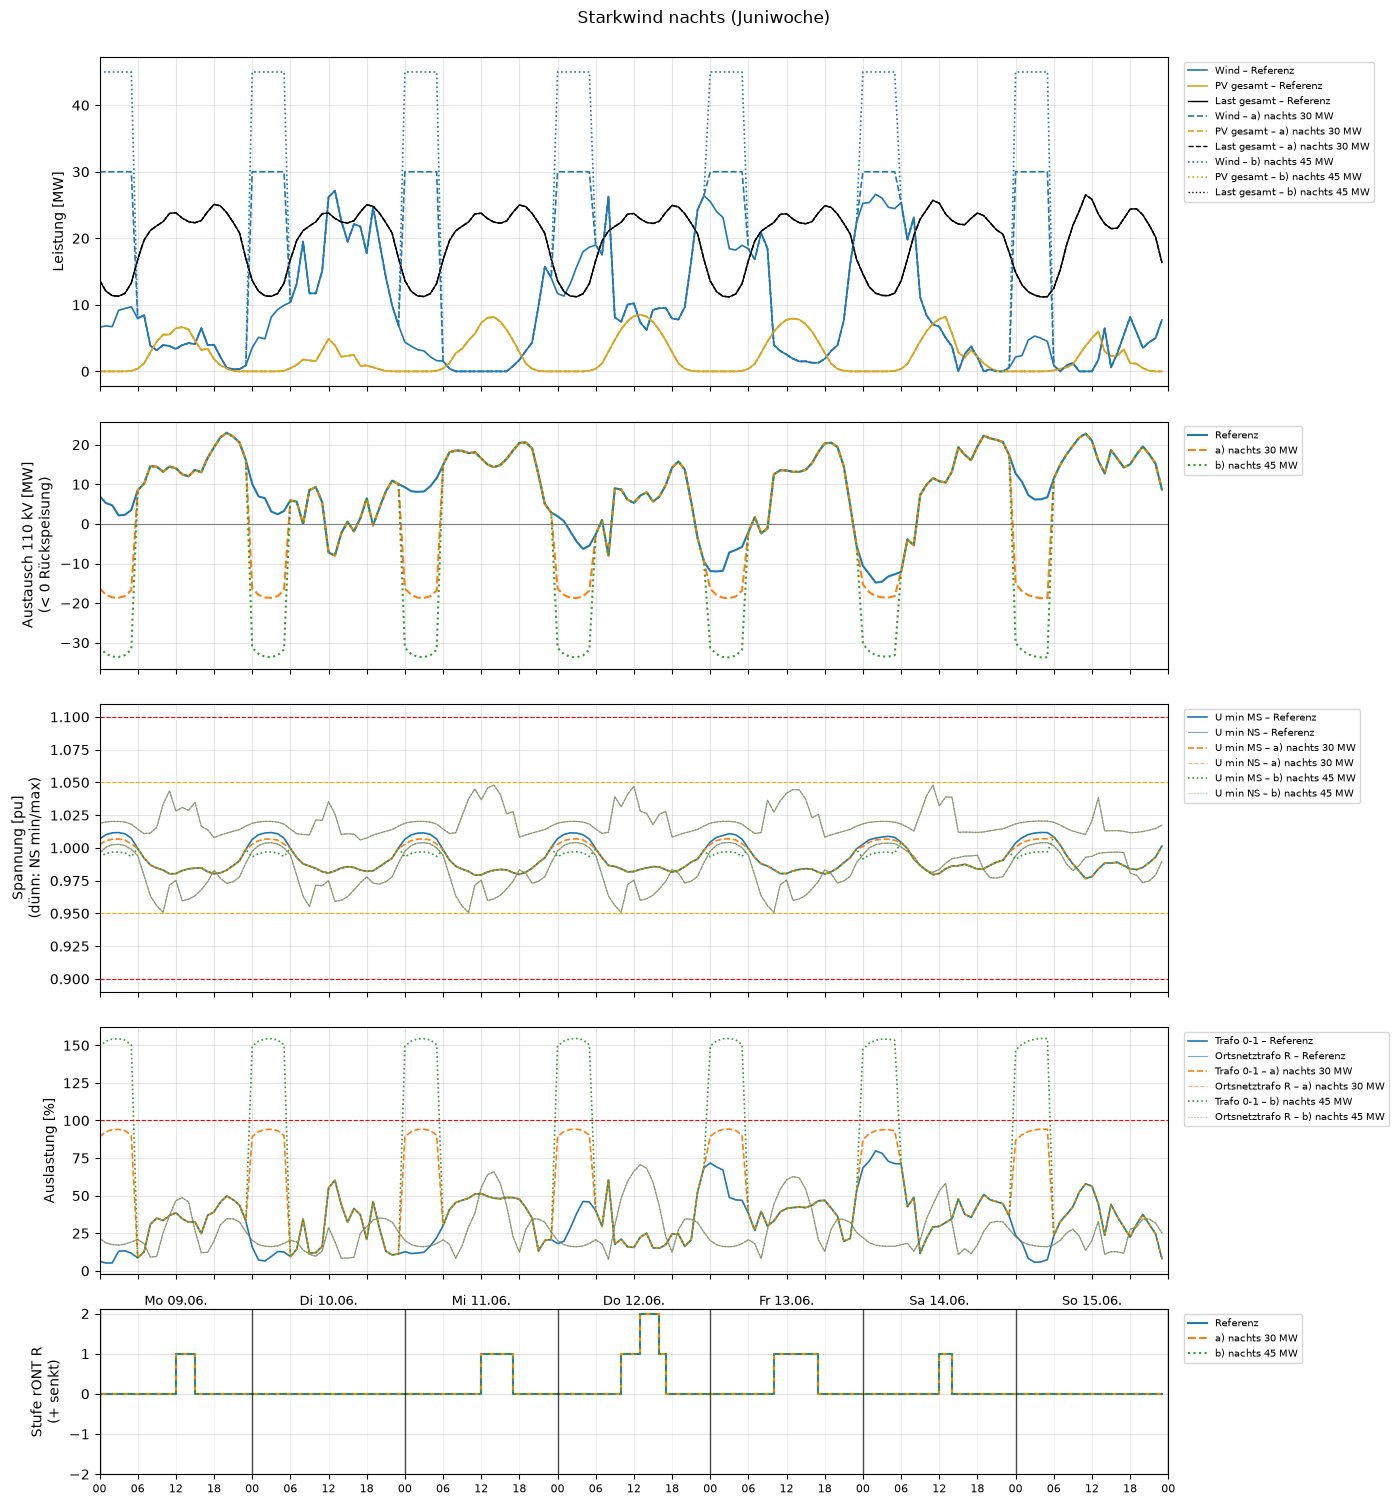

In [19]:
pr.verlauf(starkwind, "Starkwind nachts (Juniwoche)", monat="JUNE")

**Befund Starkwind nachts:**

- **a) 30 MW nachts:** Rückspeisung ins 110-kV-Netz bis 18,8 MW, in 59 statt 33 Stunden. Trafo 0-1 ist mit **94 %** höher ausgelastet als bei Höchstlast im Winter. Die MS-Spannung steigt nicht über 1,025 pu, weil der Windpark an der Sammelschiene von Trafo 0-1 einspeist und seine Leistung direkt ins 110-kV-Netz abfließt.
- **b) 45 MW nachts:** Trafo 0-1 wird mit bis zu **155 %** überlastet (42 Stunden), Rückspeisung bis 33,7 MW. Die Spannungen bleiben trotzdem im Band. Engpass ist also die thermische Grenze des Trafos (25 MVA), nicht die Spannung.
- **Prüfungsantwort:** Bei Starkwind und Schwachlast begrenzt der 110/20-kV-Trafo die Einspeisung. Ein größerer Windpark bräuchte einen eigenen Netzanschluss bzw. Umspanner oder Einspeisemanagement (Abregelung bei Überlastung, Redispatch).

## 7 Sturmabschaltung des Windparks

**Frage:** Was passiert, wenn der Windpark bei Volllast wegen Sturm abschaltet (Abschaltgeschwindigkeit überschritten)?

**Annahme:** Am Mittwoch der Januarwoche speist der Windpark von 0 bis 14 Uhr mit 30 MW ein und fällt ab 14 Uhr bis Mitternacht auf 0 MW (zwei einmalige Änderungen).

,Wind [MW],Austausch 110 kV [MW],Trafo 0-1 [MW] (p_hv),Trafo 0-1 [%],U Bus 1 [pu],U Bus 11 [pu]
11:00,30.0,-2.304,-13.952,57.794,1.009,0.965
12:00,30.0,-4.333,-13.966,57.733,1.009,0.966
13:00,30.0,-2.030,-14.443,59.330,1.010,0.968
14:00,0.0,27.809,15.263,62.394,1.008,0.967
15:00,0.0,28.705,15.417,62.994,1.008,0.967
16:00,0.0,31.129,16.594,67.821,1.007,0.962


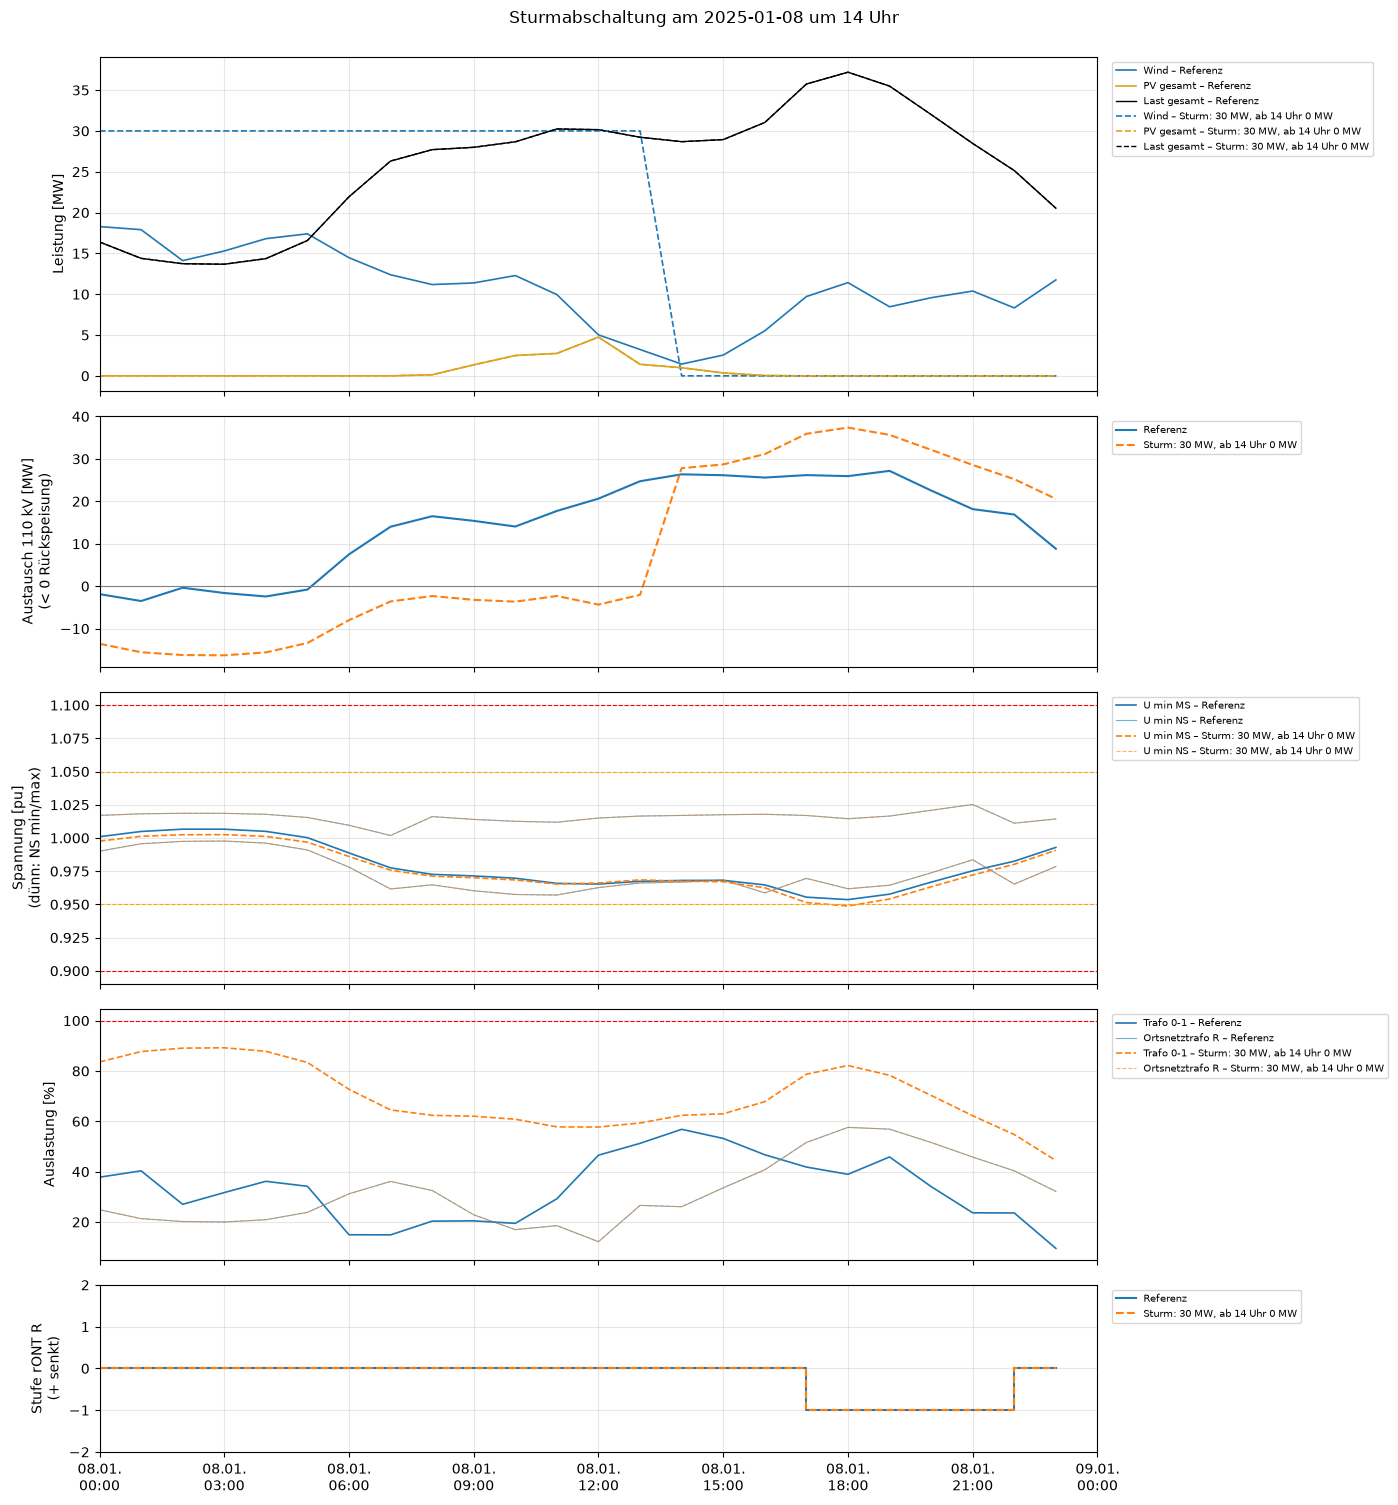

In [20]:
tag = pa.typische_wochen().loc["Januar", "Mi"]
sturm = {"Referenz": REF["JANUARY"],
         "Sturm: 30 MW, ab 14 Uhr 0 MW": pr.szenario("sturm", b, monate=["JANUARY"], aenderungen=[
             pa.einmal(WIND, wert_mw=30, datum=tag, von=0, bis=14, name="Volllast"),
             pa.einmal(WIND, wert_mw=0, datum=tag, von=14, bis=24, name="Sturmabschaltung")])}
r = sturm["Sturm: 30 MW, ab 14 Uhr 0 MW"].results
h = pd.date_range(f"{tag} 11:00", periods=6, freq="h")
display(pd.DataFrame({"Wind [MW]": r.sgen_p_mw.loc[h, "Windpark"], "Austausch 110 kV [MW]": r.ext_grid_p_mw.sum(axis=1).loc[h],
                      "Trafo 0-1 [MW] (p_hv)": r.trafo_p_mw.loc[h, "Trafo 0-1"], "Trafo 0-1 [%]": r.trafo_loading.loc[h, "Trafo 0-1"],
                      "U Bus 1 [pu]": r.vm_pu.loc[h, "Bus 1"], "U Bus 11 [pu]": r.vm_pu.loc[h, "Bus 11"]},
                     index=h).set_index(h.strftime("%H:%M")).round(3))
pr.verlauf(sturm, f"Sturmabschaltung am {tag} um 14 Uhr", tage=[tag])

**Befund Sturmabschaltung:**

- Um 14 Uhr fallen 30 MW weg: Trafo 0-1 springt von **14 MW Rückspeisung auf 15 MW Bezug**, der Austausch mit dem 110-kV-Netz von −2 auf +28 MW. Die Auslastung von Trafo 0-1 bleibt dabei fast gleich (58 → 62 %), weil nur die Richtung wechselt.
- Die Spannungen ändern sich kaum (Bus 1: 1,010 → 1,008 pu, Bus 11: 0,968 → 0,967 pu). Der Zustand danach ist der Normalbetrieb ohne Wind.
- **Prüfungsantwort:** Für das Verteilnetz ist die Sturmabschaltung unkritisch. Das Problem liegt im überlagerten Netz: 30 MW müssen schlagartig anders bereitgestellt werden (Regelleistung). Bei vielen Windparks gleichzeitig ist das ein Thema der Systemstabilität (Frequenz).

## 8 Sonniger Sonntag mit niedriger Last

**Frage:** Was passiert an einem sonnigen Sonntag, an dem viele Haushalte verreist sind? Und mit deutlich mehr PV-Haushalten (Variante „Zukunft“ aus Teil 4b)?

**Annahme (Juliwoche):** Am Sonntag verbrauchen die Haushalte im Wohngebiet nur 60 % (**a**). In **b** und **c** dasselbe Netz mit 50 % PV-Haushalten (40 % mit Speicher) statt 15 %.

In [21]:
bz = pr.basis("Zukunft")
sonntag = [pa.einmal(HAUSHALTE, faktor=0.6, monat="JULY", wochentag=6, name="Sonntag 60 % Last")]
so_tag = pa.typische_wochen().loc["Juli", "So"]
sonntag_sims = {"Referenz (heute)": REF["JULY"],
                "a) Sonntag 60 % Last (heute)": pr.szenario("sonntag_heute", b, monate=["JULY"], aenderungen=sonntag),
                "b) Zukunft, normale Last": pr.szenario("zukunft_ref", bz, monate=["JULY"]),
                "c) Zukunft, Sonntag 60 % Last": pr.szenario("sonntag_zukunft", bz, monate=["JULY"], aenderungen=sonntag)}
tab = pr.kennzahlen(sonntag_sims)
tab

,Referenz (heute),a) Sonntag 60 % Last (heute),"b) Zukunft, normale Last","c) Zukunft, Sonntag 60 % Last"
Stunden gerechnet,168,168,168,168
davon nicht konvergiert,0,0,0,0
U min MS [pu],0.978 (Bus 11),0.978 (Bus 11),0.978 (Bus 11),0.978 (Bus 11)
U max MS [pu],1.025 (Bus 1),1.025 (Bus 1),1.025 (Bus 1),1.025 (Bus 1)
U min NS [pu],0.954 (C12),0.954 (C12),0.954 (C12),0.954 (C12)
U max NS [pu],1.049 (R15),1.049 (R15),1.172 (R15),1.172 (R15)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,0,0,0
"Stunden außerhalb 0,95 … 1,05 (NS)",0,0,43,43
"Stunden außerhalb 0,90 … 1,10 (alle)",0,0,24,24
Leitung max MS [%],53.339 (Line 2-3),53.339 (Line 2-3),53.339 (Line 2-3),53.339 (Line 2-3)


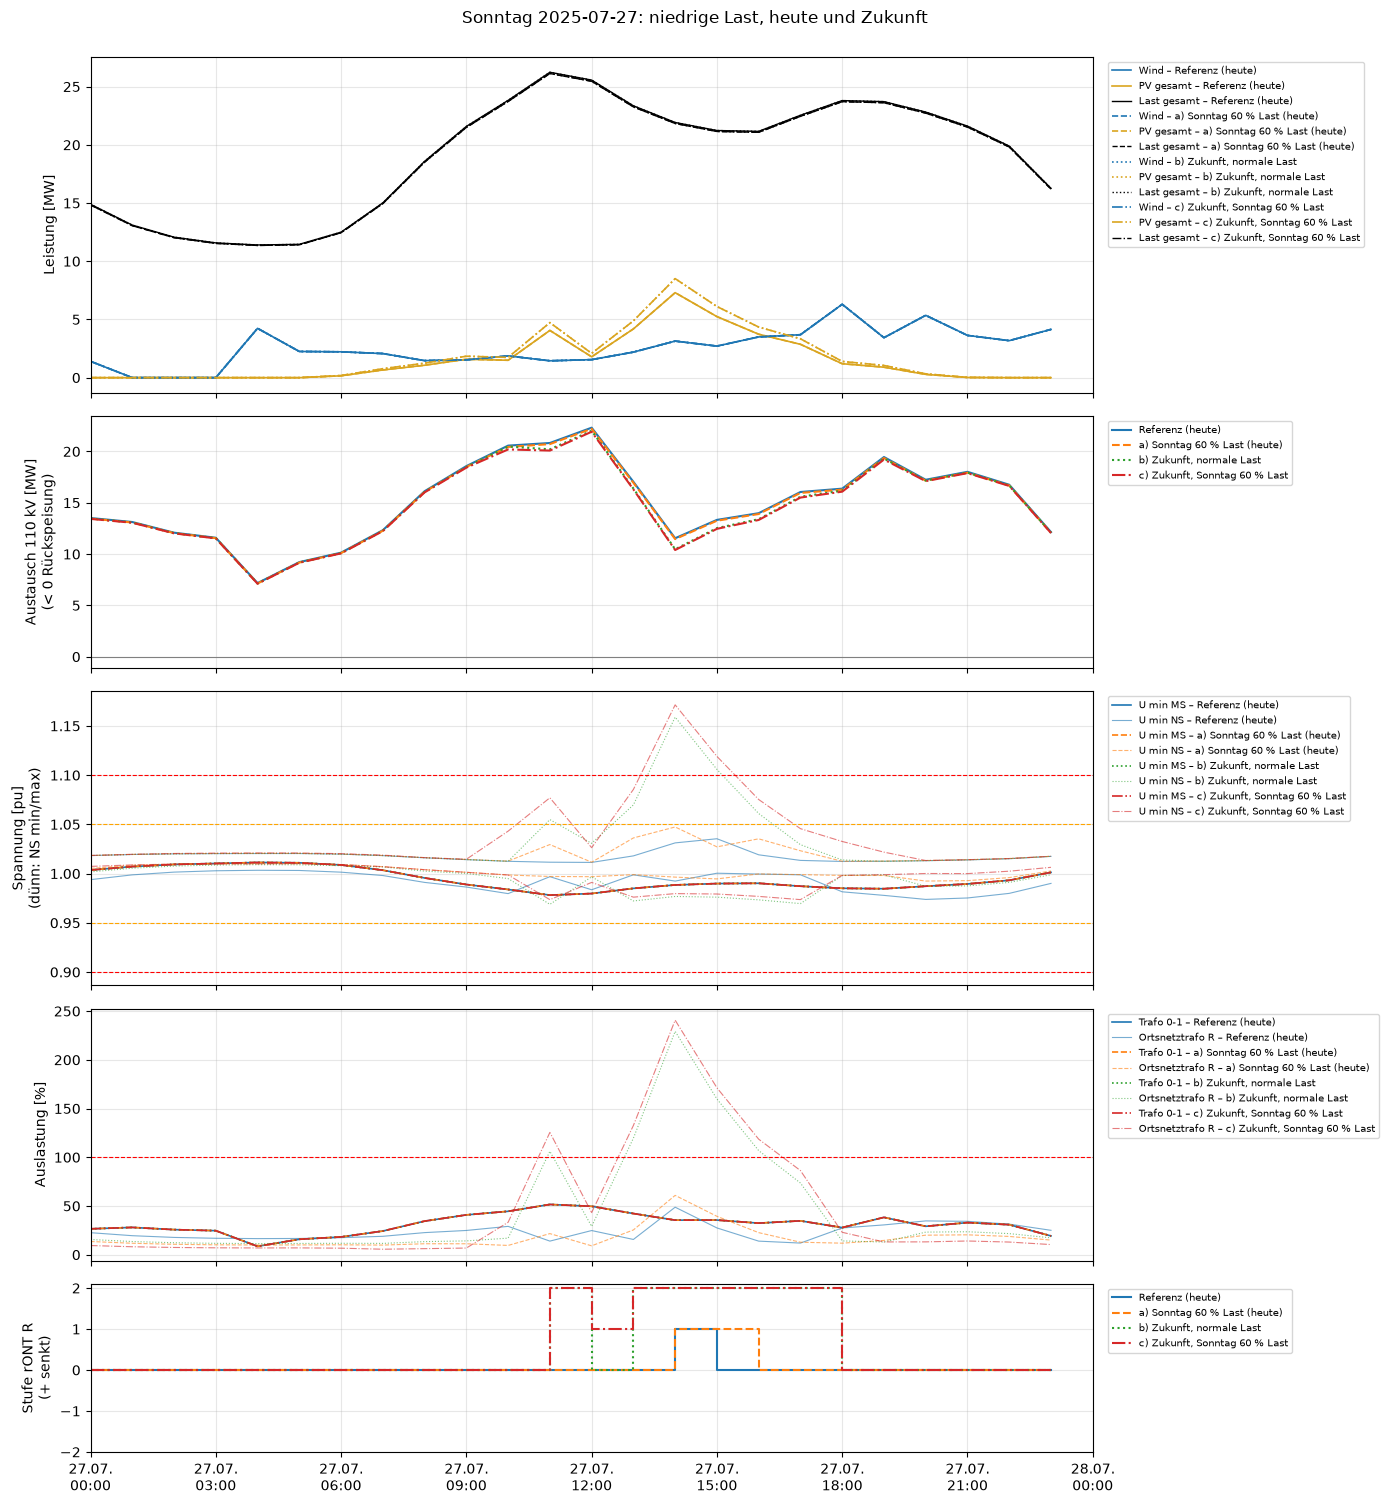

In [22]:
pr.verlauf(sonntag_sims, f"Sonntag {so_tag}: niedrige Last, heute und Zukunft", tage=[so_tag])

**Befund sonniger Sonntag:**

- **Heute:** Weniger Last am Sonntag ändert wenig: Rückspeisung bis 375 statt 360 kW, U max 1,049 pu. Der rONT hält die Spannung im Band. Die PV-Leistung ist mittags ohnehin viel größer als der Verbrauch, 40 % weniger Last machen nur einen kleinen Teil davon aus.
- **Zukunft (50 % PV-Haushalte):** Schon an normalen Tagen speist das Wohngebiet bis **1,47 MW** zurück. Ortsnetztrafo R wird mit bis zu **247 %** belastet, Kabel R2-R3 mit 245 %, in 43 Stunden überlastet. Die Spannung an R15 steigt auf **1,17 pu**, in 24 Stunden über 1,10 pu, obwohl der rONT auf der höchsten Stufe steht.
- **Prüfungsantwort:** Der kritische Fall im Wohngebiet ist Sonne bei geringer Last, nicht Höchstlast. Mit wachsendem PV-Anteil reicht der rONT nicht mehr; nötig sind netzdienliche Speicher (laden erst zur Mittagsspitze), Wirkleistungsbegrenzung der Wechselrichter, Q(U)-Regelung oder Netzausbau.

## 9 S1 wird bei viel Wind geschlossen

**Frage:** Was passiert, wenn der Netzbetreiber den Trennschalter S1 schließt, während viel Wind weht?

**Annahme:** Dezemberwoche (windreich), S1 dauerhaft geschlossen, sonst unverändert.

In [23]:
s1 = {"Referenz (S1 offen)": REF["DECEMBER"],
      "S1 geschlossen": pr.szenario("s1_zu", b, monate=["DECEMBER"], netz=lambda s: s.changeParameter("S1", "closed", True))}
tab = pr.kennzahlen(s1)
display(tab)
r0, r1 = (s.results for s in s1.values())
richtung = {}
for l in ("Line 1-2", "Line 2-3", "Line 3-8", "Line 14-8", "Line 12-13", "Line 13-14"):
    richtung[l] = {"S1 offen: h mit p_from > 0": int((r0.line_p_mw[l] > 0.001).sum()), "S1 offen: h mit p_from < 0": int((r0.line_p_mw[l] < -0.001).sum()),
                   "S1 zu: h mit p_from > 0": int((r1.line_p_mw[l] > 0.001).sum()), "S1 zu: h mit p_from < 0": int((r1.line_p_mw[l] < -0.001).sum()),
                   "max. Auslastung S1 offen [%]": r0.line_loading[l].max(), "max. Auslastung S1 zu [%]": r1.line_loading[l].max()}
print("Flussrichtung (p_from > 0: vom ersten zum zweiten Bus im Namen) und Auslastung:")
pd.DataFrame(richtung).T.round(1)

,Referenz (S1 offen),S1 geschlossen
Stunden gerechnet,168,168
davon nicht konvergiert,0,0
U min MS [pu],0.952 (Bus 11),0.976 (Bus 6)
U max MS [pu],1.023 (Bus 1),1.029 (Bus 1)
U min NS [pu],0.951 (R15),0.951 (R15)
U max NS [pu],1.027 (R15),1.024 (R1)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,0
"Stunden außerhalb 0,95 … 1,05 (NS)",0,0
"Stunden außerhalb 0,90 … 1,10 (alle)",0,0
Leitung max MS [%],76.881 (Line 2-3),97.538 (Line 1-2)


Flussrichtung (p_from > 0: vom ersten zum zweiten Bus im Namen) und Auslastung:


,S1 offen: h mit p_from > 0,S1 offen: h mit p_from < 0,S1 zu: h mit p_from > 0,S1 zu: h mit p_from < 0,max. Auslastung S1 offen [%],max. Auslastung S1 zu [%]
Line 1-2,168.0,0.0,168.0,0.0,76.5,97.5
Line 2-3,168.0,0.0,168.0,0.0,76.9,97.3
Line 3-8,168.0,0.0,168.0,0.0,36.3,66.1
Line 14-8,0.0,0.0,67.0,101.0,0.0,43.1
Line 12-13,168.0,0.0,85.0,83.0,7.6,42.2
Line 13-14,168.0,0.0,83.0,85.0,7.1,42.2


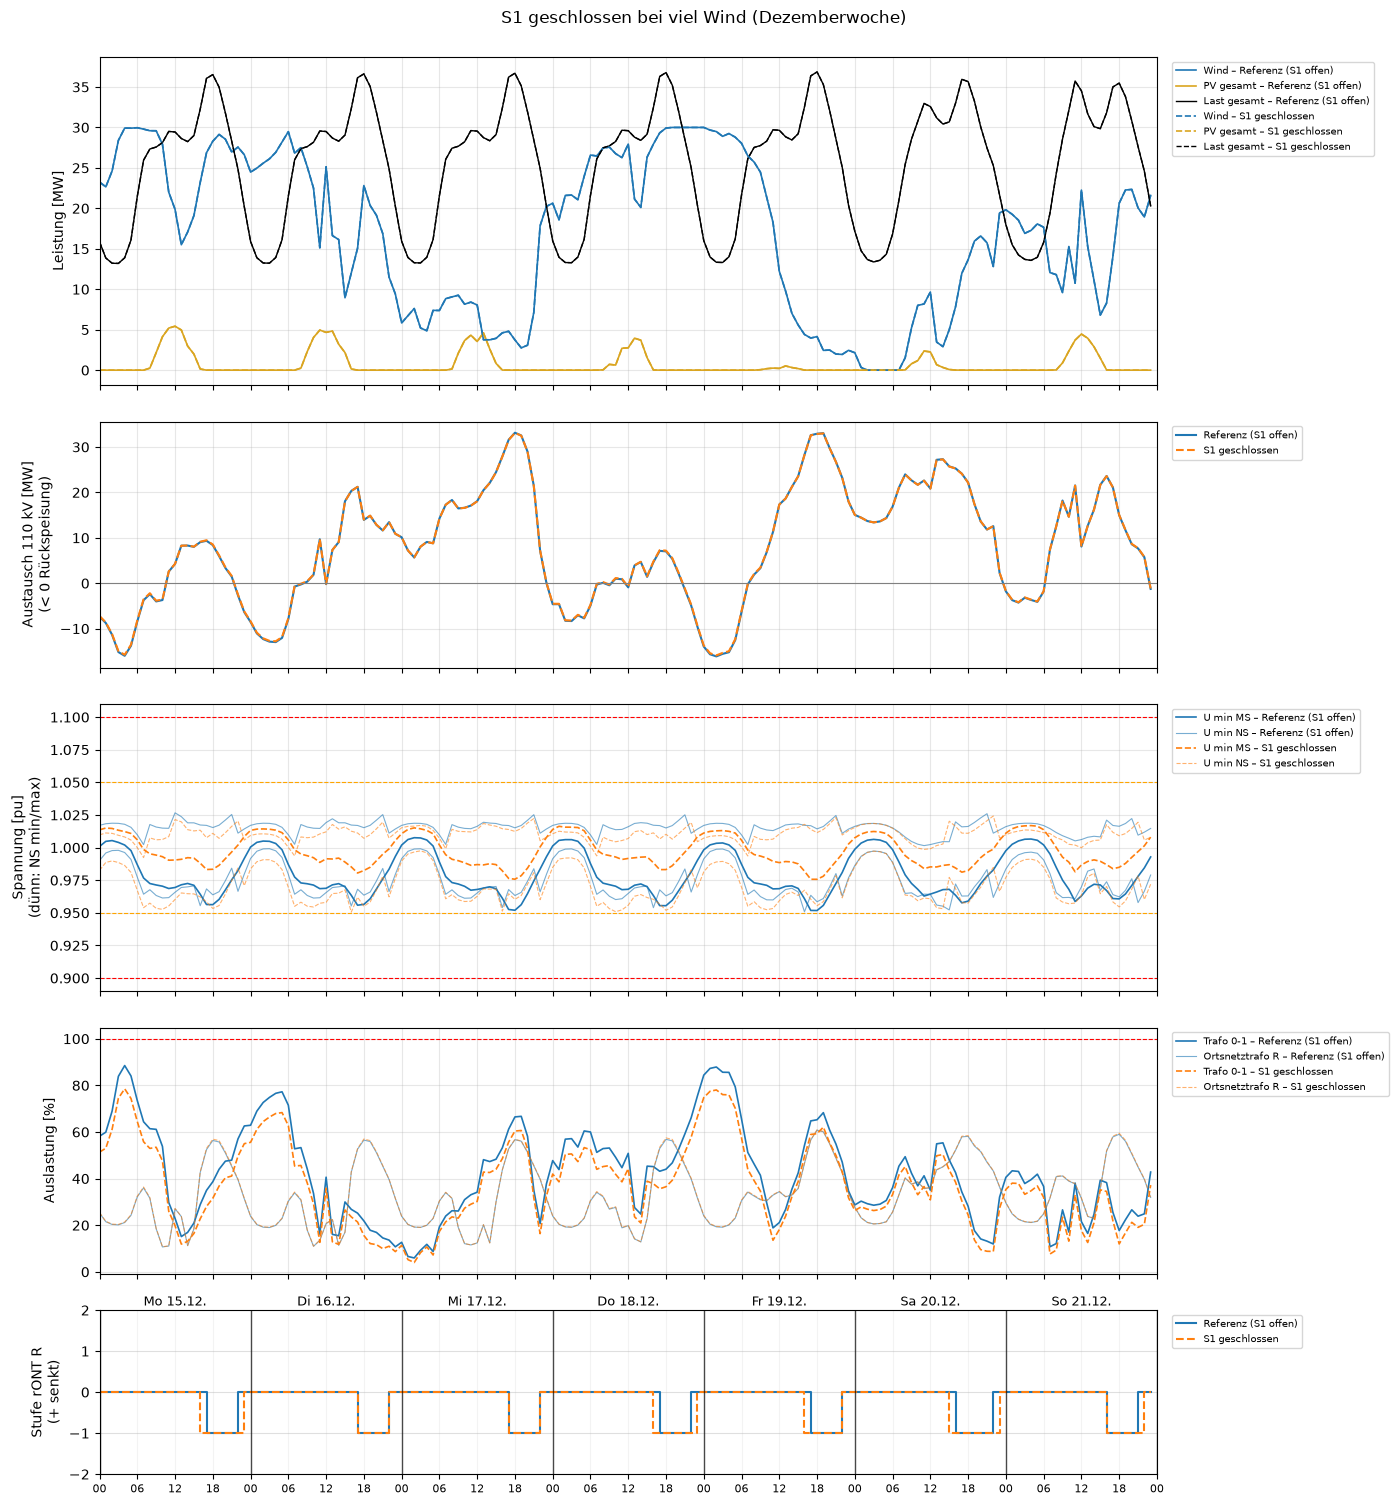

In [24]:
pr.verlauf(s1, "S1 geschlossen bei viel Wind (Dezemberwoche)", monat="DECEMBER")

**Befund S1 bei viel Wind:**

- **Auslastung:** Line 1-2 und 2-3 steigen von 77 auf **97,5 %**, Line 3-8 von 36 auf 66 %. Der Windstrom fließt jetzt auch durch Abgang 1 und über die Kupplung (Line 14-8) zu Trafo 0-12. Trafo 0-1 wird entlastet (88,5 → 78,5 %), Trafo 0-12 stärker belastet (70 → 76 %).
- **Flussrichtung:** Auf der Kupplung und in Abgang 2 (Line 12-13, 13-14) wechselt die Richtung je nach Wind (Tabelle). Bei offenem S1 fließt dort immer Leistung vom Umspannwerk weg.
- **Spannung:** Abgang 1 wird angehoben (U min 0,976 statt 0,952 pu), weil er von zwei Seiten versorgt wird.
- **Verluste:** + 63 % (16,8 → 27,3 MWh), weil Leistung über den langen Ring fließt.
- **Prüfungsantwort:** S1 verbessert die Spannung, kostet aber Verluste und bringt Line 1-2 an die Grenze. Mit Windpark bleibt S1 im Normalbetrieb offen.

## 10 Ausfall von Line 2-3

**Frage:** Was passiert, wenn Line 2-3 ausfällt?

**Annahme:** Januarwoche, Line 2-3 außer Betrieb. **a)** ohne Wiederversorgung: Bus 3 bis 11 sind getrennt (sofern nicht über S2/S3 versorgt). **b)** mit Wiederversorgung nach dem Plan aus Teil 3b/4a: S1 wird geschlossen.

In [25]:
def line23(s):
    s.changeParameter("Line 2-3", "in_service", False)

def line23_s1(s):
    line23(s)
    s.changeParameter("S1", "closed", True)

leitung = {"Referenz": REF["JANUARY"],
           "a) Line 2-3 aus": pr.szenario("line23_aus", b, monate=["JANUARY"], netz=line23),
           "b) Line 2-3 aus, S1 zu": pr.szenario("line23_s1", b, monate=["JANUARY"], netz=line23_s1)}
r = leitung["a) Line 2-3 aus"].results
print("ohne Wiederversorgung nicht versorgte Busse (Spannung NaN):",
      [c for c in r.vm_pu.columns if r.vm_pu[c].isna().all() and not c.startswith("LV")])
tab = pr.kennzahlen(leitung)
tab

Hinweis: 9 Busse sind nicht versorgt (z. B. ['Bus 3', 'Bus 4', 'Bus 5', 'Bus 6', 'Bus 7']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
ohne Wiederversorgung nicht versorgte Busse (Spannung NaN): ['Bus 3', 'Bus 4', 'Bus 5', 'Bus 6', 'Bus 7', 'Bus 8', 'Bus 9', 'Bus 10', 'Bus 11']


,Referenz,a) Line 2-3 aus,"b) Line 2-3 aus, S1 zu"
Stunden gerechnet,168,168,168
davon nicht konvergiert,0,0,0
U min MS [pu],0.952 (Bus 11),1.001 (Bus 14),0.926 (Bus 6)
U max MS [pu],1.023 (Bus 1),1.024 (Bus 2),1.024 (Bus 2)
U min NS [pu],0.950 (R15),0.950 (R15),0.950 (I2)
U max NS [pu],1.026 (R1),1.026 (R1),1.037 (R1)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,0,70
"Stunden außerhalb 0,95 … 1,05 (NS)",0,0,0
"Stunden außerhalb 0,90 … 1,10 (alle)",0,0,0
Leitung max MS [%],78.491 (Line 2-3),7.953 (Line 12-13),65.626 (Line 12-13)


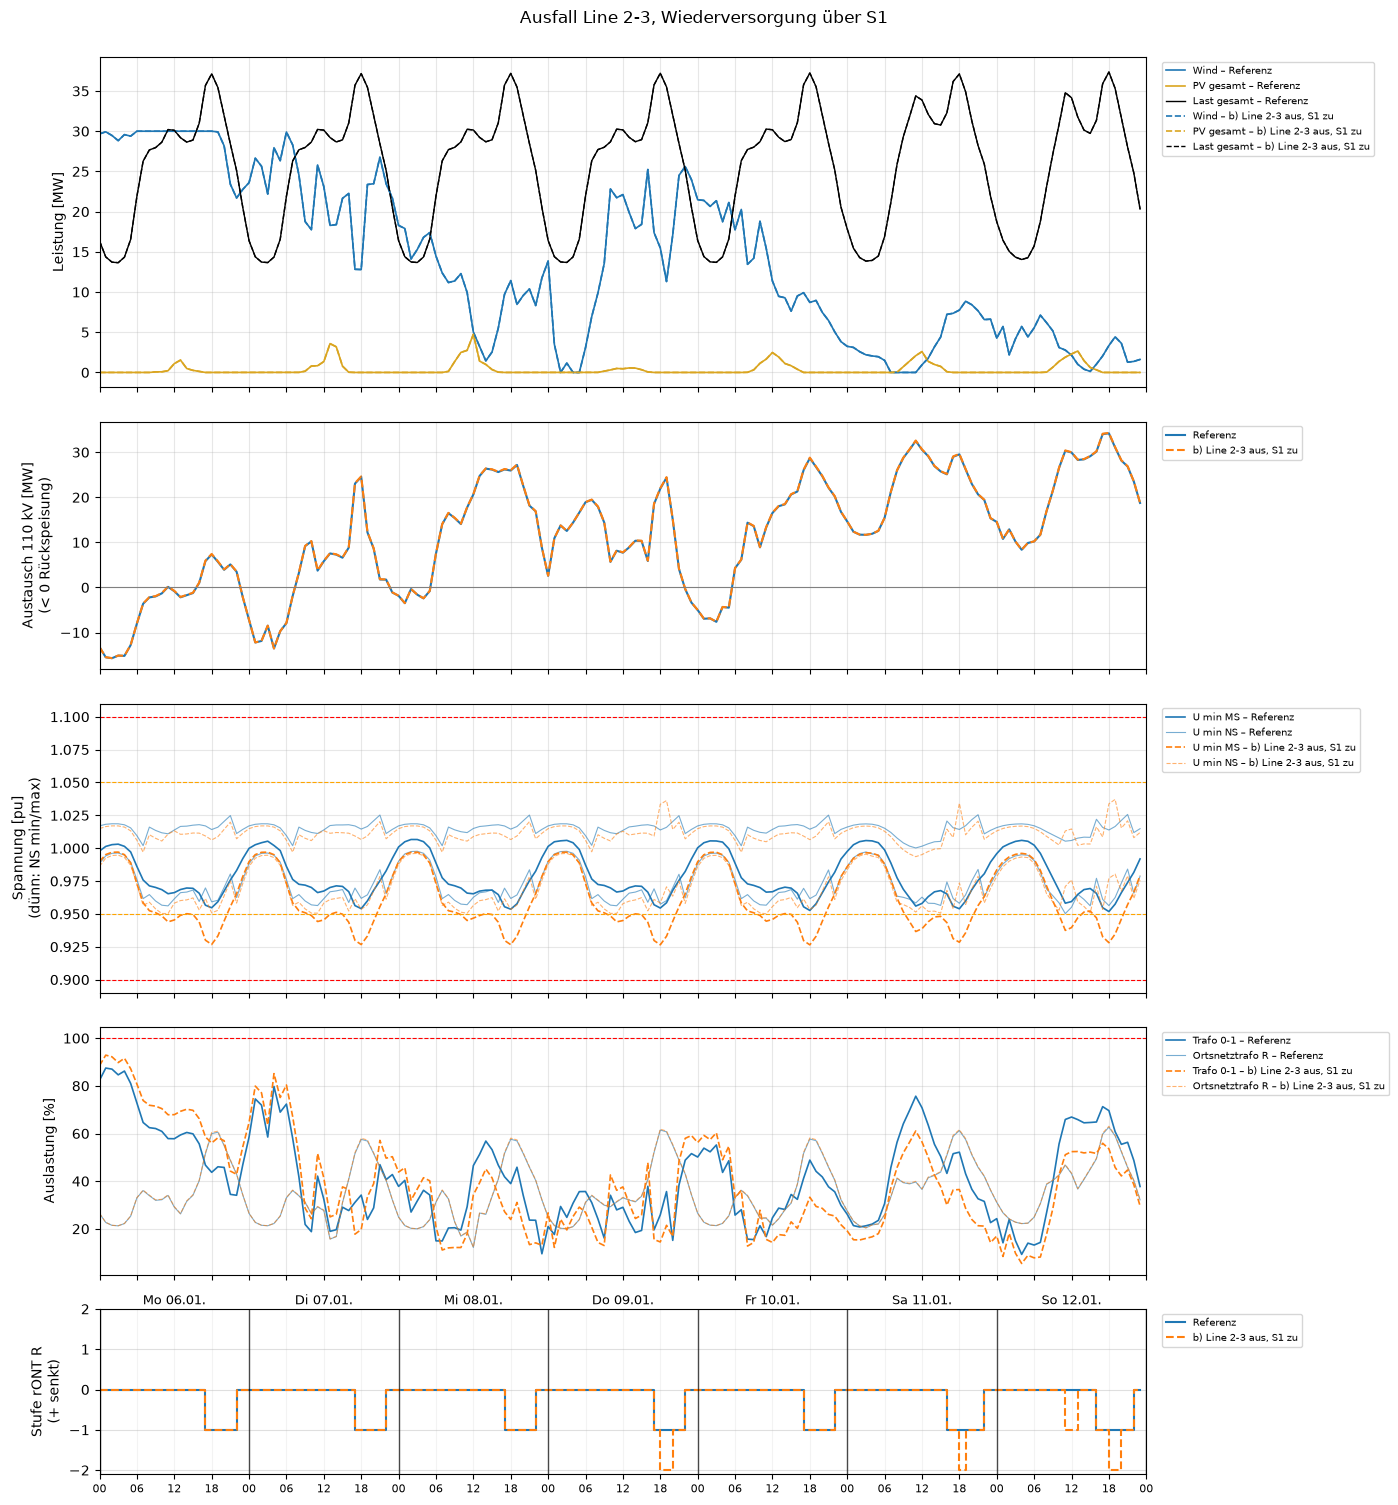

In [26]:
pr.verlauf({k: leitung[k] for k in ("Referenz", "b) Line 2-3 aus, S1 zu")}, "Ausfall Line 2-3, Wiederversorgung über S1", monat="JANUARY")

**Befund Ausfall Line 2-3:**

- **a) ohne Wiederversorgung:** Bus 3 bis 11 sind ohne Versorgung (Spannung NaN). Der Rest des Netzes läuft normal weiter; die Kennzahlen gelten nur für die versorgten Busse.
- **b) Wiederversorgung über S1:** Bus 3 bis 11 werden über Abgang 2 und die Kupplung versorgt. Das funktioniert: keine Überlastung (Trafo 0-12 bis 87 %, Line 12-13 bis 66 %), aber die Spannung fällt am Ende des langen Wegs auf **0,926 pu an Bus 6**, in 70 Stunden unter 0,95 pu. Die Arbeitsgrenze 0,90 pu wird eingehalten. Die rONT schalten häufiger (38 statt 24), weil Bus 12 tiefer liegt.
- **Prüfungsantwort:** Der (n-1)-Fall ist beherrschbar, aber nur im Arbeitsband, nicht im Planungsband. Die Verluste steigen um gut 50 %.

## 11 Ausfall von Trafo 0-1

**Frage:** Was passiert, wenn der 110/20-kV-Trafo von Abgang 1 ausfällt?

**Annahme:** Januarwoche, Trafo 0-1 außer Betrieb, S1 geschlossen (einzige Möglichkeit, Abgang 1 zu versorgen). **a)** Windpark speist weiter ein, **b)** Windpark abgeschaltet.

In [27]:
def trafo01(s):
    s.changeParameter("Trafo 0-1", "in_service", False)
    s.changeParameter("S1", "closed", True)

def trafo01_ohne_wind(s):
    trafo01(s)
    s.changeParameter("Windpark", "in_service", False)

trafo = {"Referenz": REF["JANUARY"],
         "a) Trafo 0-1 aus, S1 zu": pr.szenario("trafo01_aus", b, monate=["JANUARY"], netz=trafo01),
         "b) zusätzlich Windpark aus": pr.szenario("trafo01_aus_ohne_wind", b, monate=["JANUARY"], netz=trafo01_ohne_wind)}
tab = pr.kennzahlen(trafo)
tab

,Referenz,"a) Trafo 0-1 aus, S1 zu",b) zusätzlich Windpark aus
Stunden gerechnet,168,168,168
davon nicht konvergiert,0,45,138
U min MS [pu],0.952 (Bus 11),0.519 (Bus 1),0.594 (Bus 1)
U max MS [pu],1.023 (Bus 1),1.245 (Bus 1),1.002 (Bus 12)
U min NS [pu],0.950 (R15),0.932 (R15),0.956 (R15)
U max NS [pu],1.026 (R1),1.026 (R1),0.998 (I1)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,103,30
"Stunden außerhalb 0,95 … 1,05 (NS)",0,10,0
"Stunden außerhalb 0,90 … 1,10 (alle)",0,83,30
Leitung max MS [%],78.491 (Line 2-3),379.428 (Line 1-2),258.511 (Line 3-8)


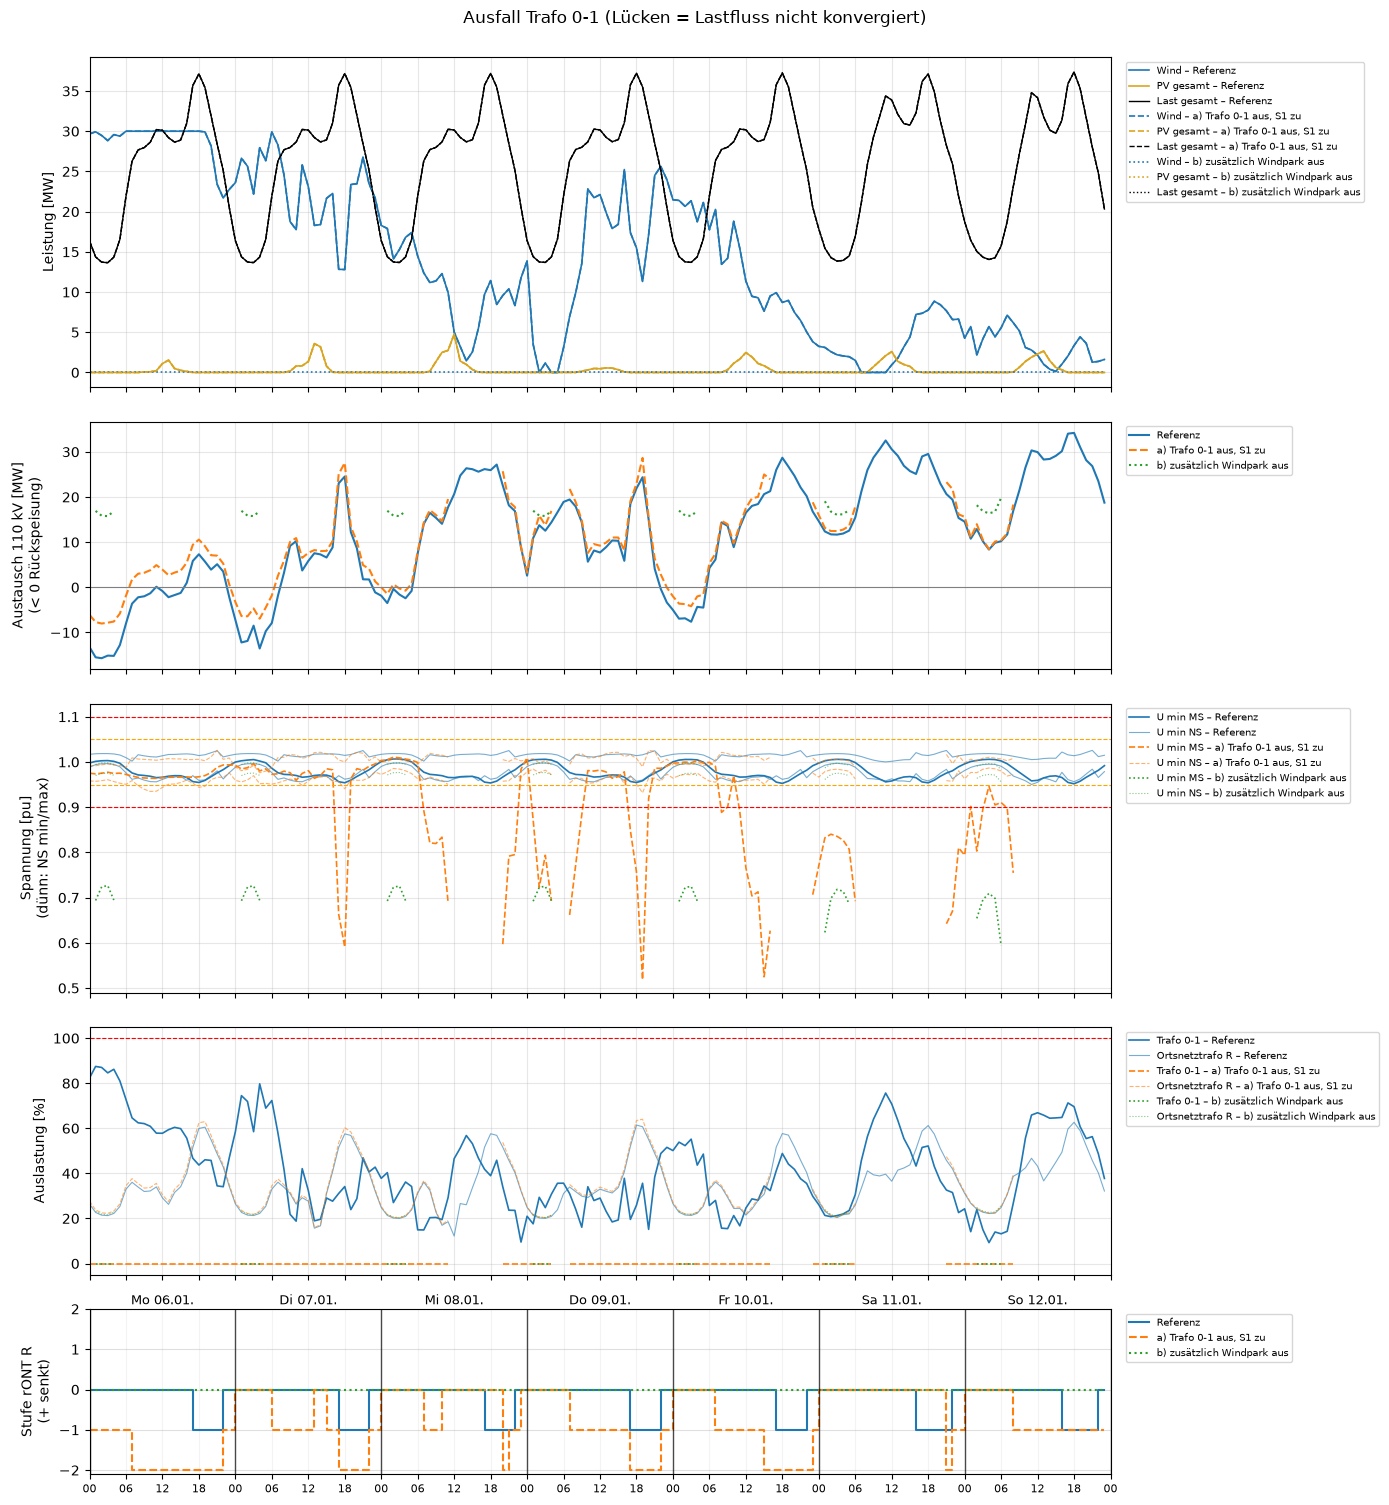

In [28]:
pr.verlauf(trafo, "Ausfall Trafo 0-1 (Lücken = Lastfluss nicht konvergiert)", monat="JANUARY")

**Befund Ausfall Trafo 0-1:**

- **a) Windpark speist weiter:** In 45 von 168 Stunden konvergiert der Lastfluss nicht. Bei Wind hebt der Windpark Bus 1 bis **1,25 pu** an, Line 1-2 wird mit bis zu **379 %** belastet, Trafo 0-12 mit 130 %. Bei wenig Wind bricht die Spannung bis 0,52 pu ein.
- **b) Windpark abgeschaltet:** Die Überspannung verschwindet, aber jetzt muss die ganze Last von Abgang 1 über den langen Weg fließen: In **138 Stunden** keine Lösung, sonst Spannung bis 0,59 pu und Line 3-8 mit 259 %.
- **Prüfungsantwort:** Die Kupplung am Ende der Abgänge kann keinen ganzen Abgang übernehmen. Der Ausfall eines 110/20-kV-Trafos ist mit S1 nicht beherrschbar; nötig wäre eine Kupplung im Umspannwerk (beide Trafos auf eine Sammelschiene) oder ein dritter Trafo.

## 12 Der Stufenschalter fällt aus

**Frage:** Was passiert, wenn die rONT nicht mehr regeln (Stufenschalter klemmt in Mittelstellung)?

**Annahme:** Alle drei Ortsnetztrafos bleiben auf Stufe 0, im Winter (Januar, Abendspitze) und im Sommer (Juli, Rückspeisung).

In [29]:
ront = {"Januar: mit rONT": REF["JANUARY"],
        "Januar: Stufe fest 0": pr.szenario("ohne_ront_jan", b, monate=["JANUARY"], regler=False),
        "Juli: mit rONT": REF["JULY"],
        "Juli: Stufe fest 0": pr.szenario("ohne_ront_jul", b, monate=["JULY"], regler=False)}
tab = pr.kennzahlen(ront)
tab

,Januar: mit rONT,Januar: Stufe fest 0,Juli: mit rONT,Juli: Stufe fest 0
Stunden gerechnet,168,168,168,168
davon nicht konvergiert,0,0,0,0
U min MS [pu],0.952 (Bus 11),0.952 (Bus 11),0.978 (Bus 11),0.978 (Bus 11)
U max MS [pu],1.023 (Bus 1),1.023 (Bus 1),1.025 (Bus 1),1.025 (Bus 1)
U min NS [pu],0.950 (R15),0.928 (R15),0.954 (C12),0.954 (C12)
U max NS [pu],1.026 (R1),1.019 (I1),1.049 (R15),1.065 (R15)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,0,0,0
"Stunden außerhalb 0,95 … 1,05 (NS)",0,70,0,10
"Stunden außerhalb 0,90 … 1,10 (alle)",0,0,0,0
Leitung max MS [%],78.491 (Line 2-3),78.491 (Line 2-3),53.339 (Line 2-3),53.339 (Line 2-3)


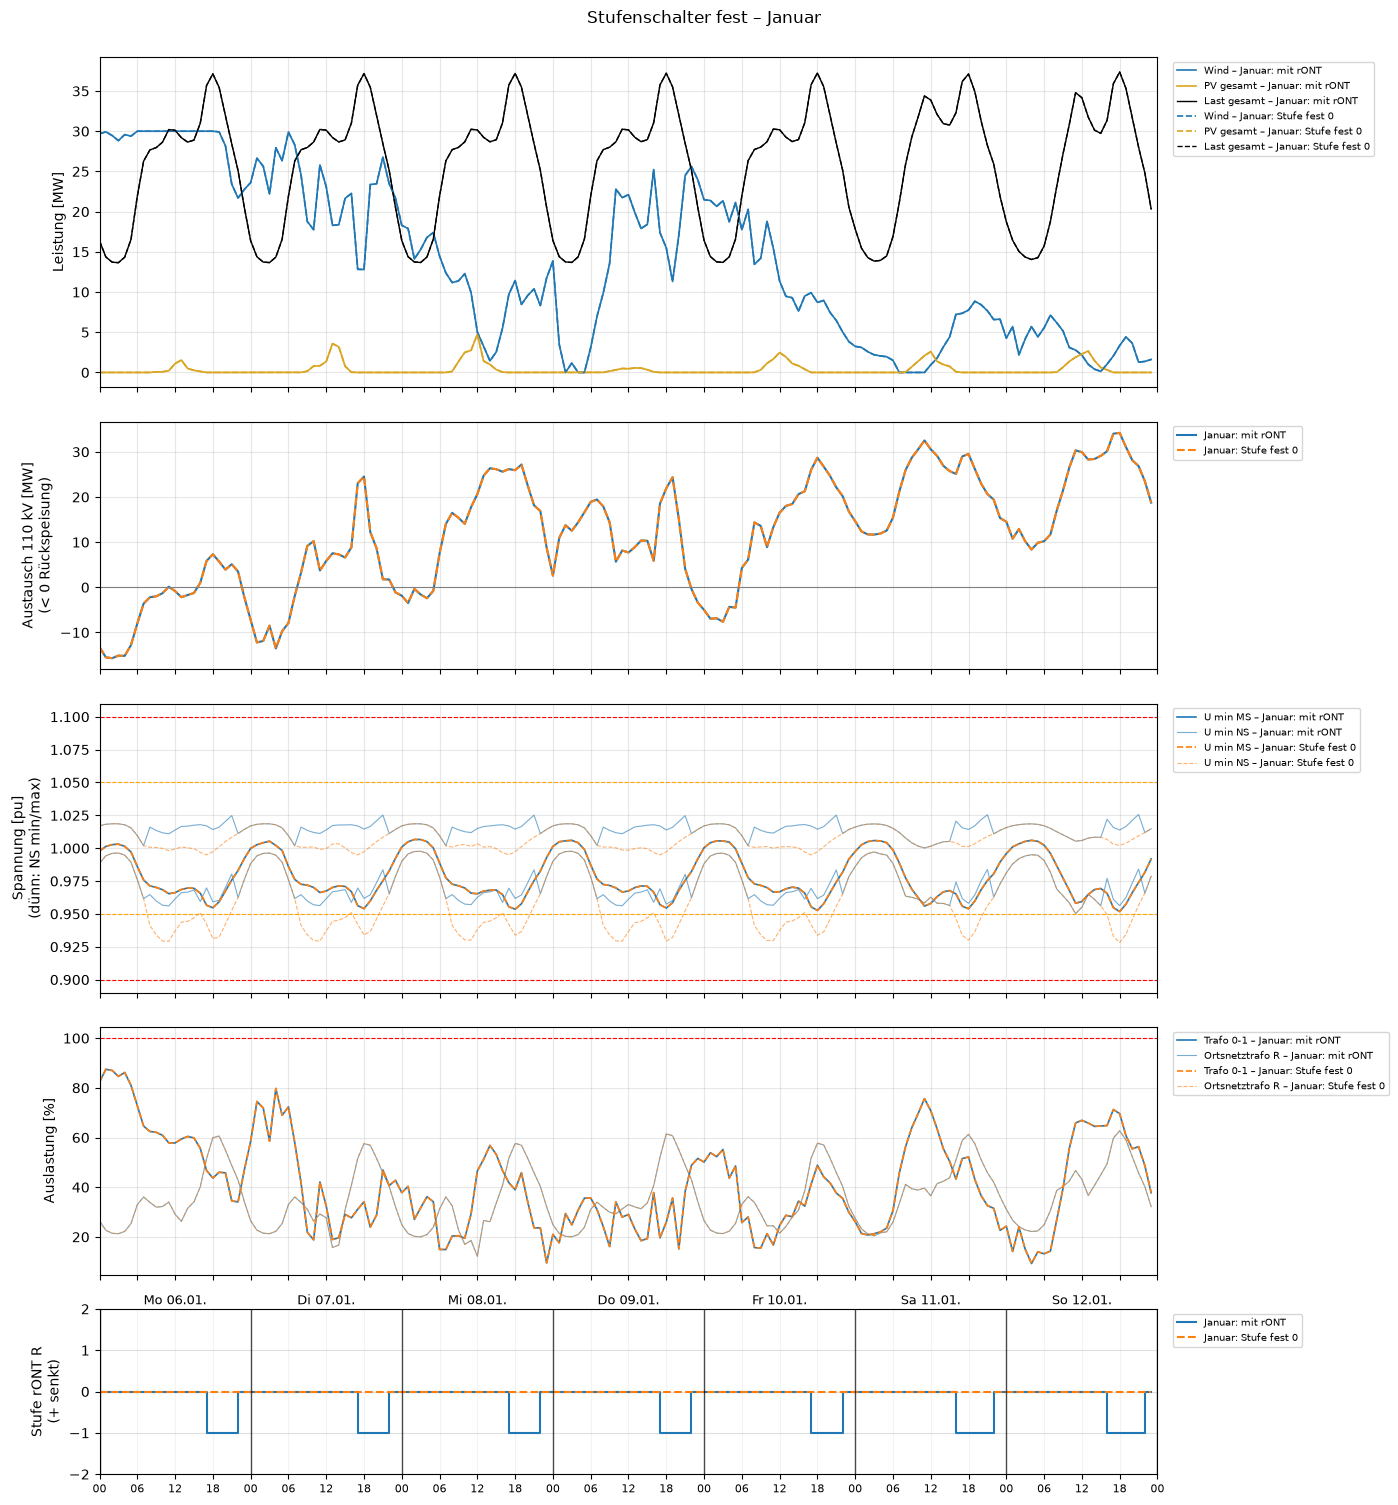

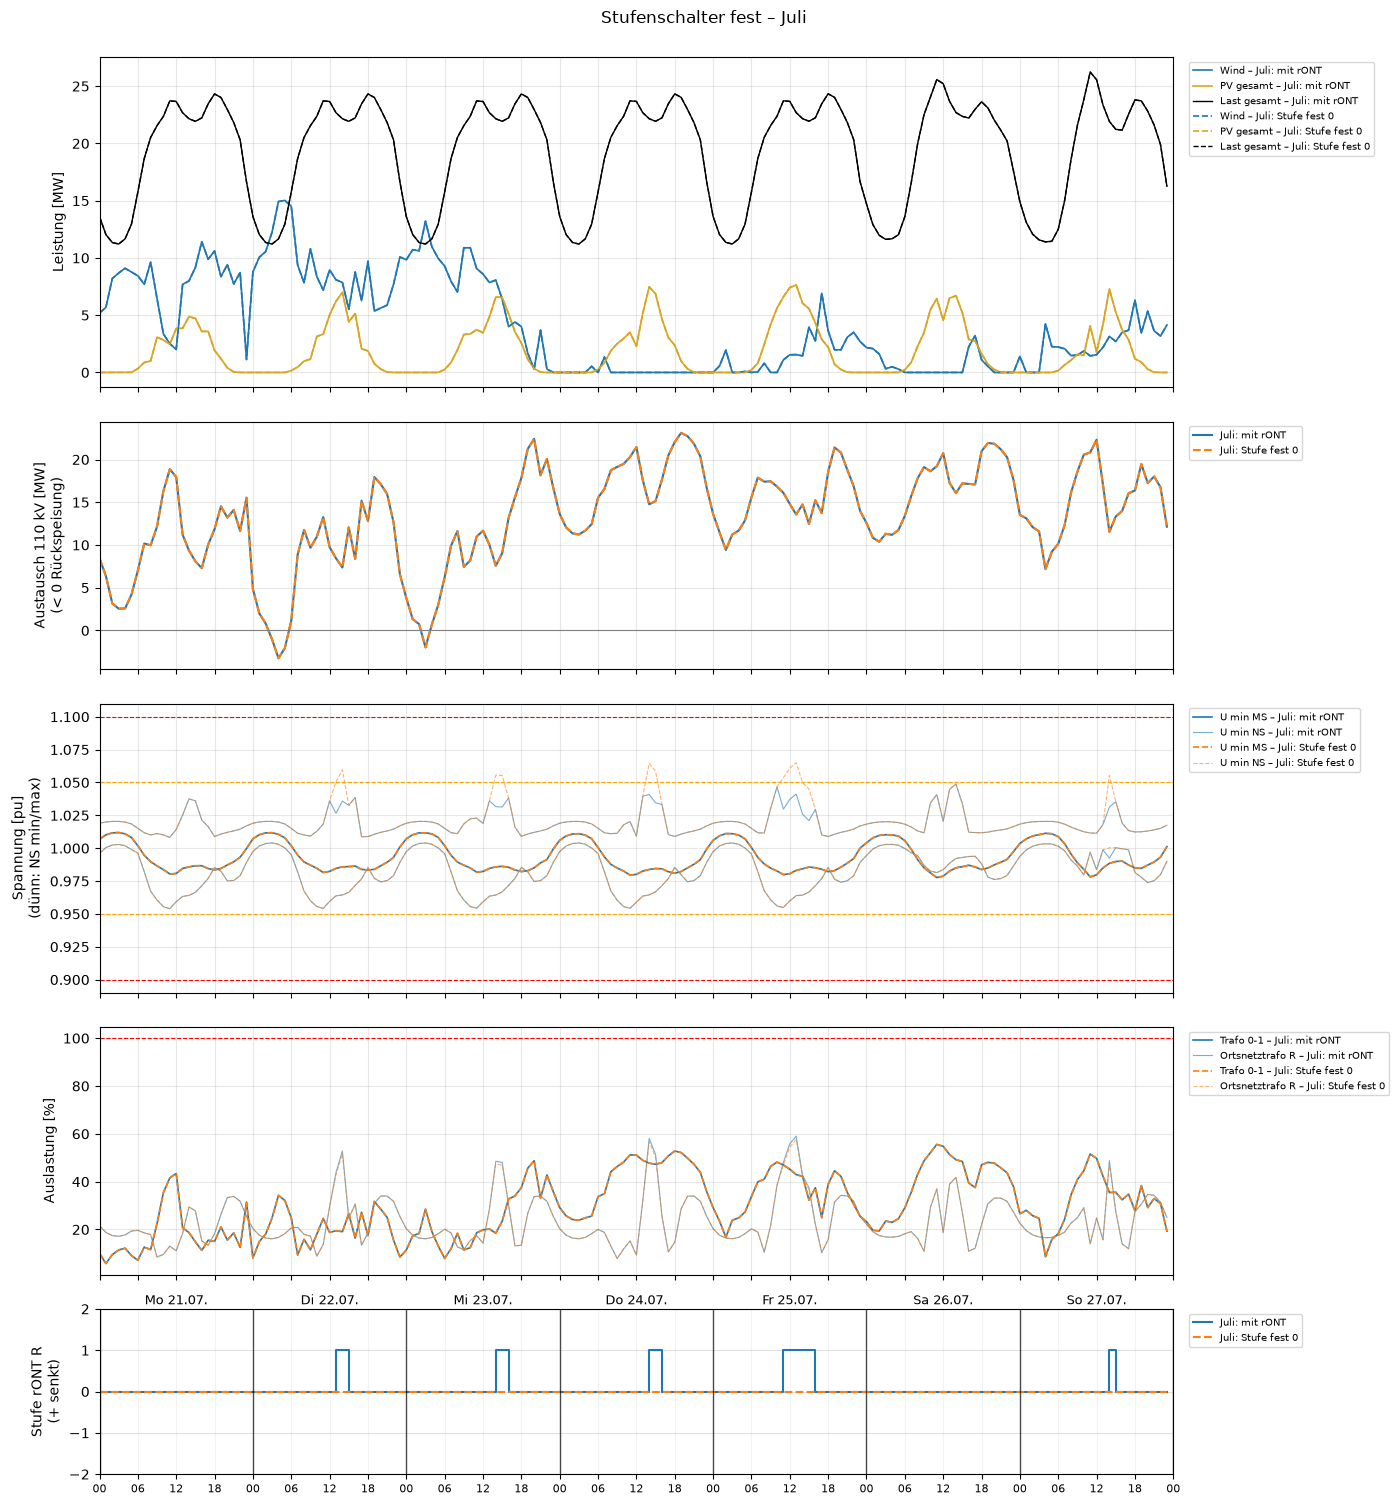

In [30]:
pr.verlauf({k: ront[k] for k in list(ront)[:2]}, "Stufenschalter fest – Januar", monat="JANUARY")
pr.verlauf({k: ront[k] for k in list(ront)[2:]}, "Stufenschalter fest – Juli", monat="JULY")

**Befund Stufenschalter fest:**

- **Januar:** Ohne Regelung fällt die Spannung an R15 zur Abendspitze auf **0,928 pu** (unter das Planungsband, über der Arbeitsgrenze).
- **Juli:** Mittags steigt sie bei Rückspeisung auf **1,065 pu**.
- Im MS-Netz ändert sich nichts.
- **Prüfungsantwort:** Der rONT regelt jetzt in beide Richtungen. Fällt er aus, liegt das Wohngebiet im Winter zu tief und im Sommer zu hoch, die Arbeitsgrenzen 0,90 … 1,10 pu werden heute aber noch eingehalten.

## 13 Windpark mit Blindleistungsbezug

**Frage:** Was passiert, wenn der Windpark mit cos φ = 0,95 untererregt betrieben wird (Blindleistung aufnimmt)?

**Annahme:** Januarwoche, Windpark cos φ = −0,95 (untererregt), sonst unverändert.

In [31]:
blind = {"Referenz (cos φ = 1)": REF["JANUARY"],
         "cos φ = 0,95 untererregt": pr.szenario("wind_cosphi", b, monate=["JANUARY"],
             netz=lambda s: s.changeParameter("Windpark", "cos_phi", -0.95))}
tab = pr.kennzahlen(blind)
display(tab)
r0, r1 = (s.results for s in blind.values())
pd.DataFrame({"Q Windpark max [Mvar]": [-r0.sgen_q_mvar["Windpark"].min(), -r1.sgen_q_mvar["Windpark"].min()],
              "Q aus 110 kV max [Mvar]": [r0.ext_grid_q_mvar.sum(axis=1).max(), r1.ext_grid_q_mvar.sum(axis=1).max()]},
             index=list(blind)).round(2)

,Referenz (cos φ = 1),"cos φ = 0,95 untererregt"
Stunden gerechnet,168,168
davon nicht konvergiert,0,0
U min MS [pu],0.952 (Bus 11),0.900 (Bus 11)
U max MS [pu],1.023 (Bus 1),1.022 (Bus 12)
U min NS [pu],0.950 (R15),0.950 (R15)
U max NS [pu],1.026 (R1),1.026 (R1)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,70
"Stunden außerhalb 0,95 … 1,05 (NS)",0,0
"Stunden außerhalb 0,90 … 1,10 (alle)",0,1
Leitung max MS [%],78.491 (Line 2-3),81.960 (Line 2-3)


,Q Windpark max [Mvar],Q aus 110 kV max [Mvar]
Referenz (cos φ = 1),-0.00,11.26
"cos φ = 0,95 untererregt",9.86,21.70


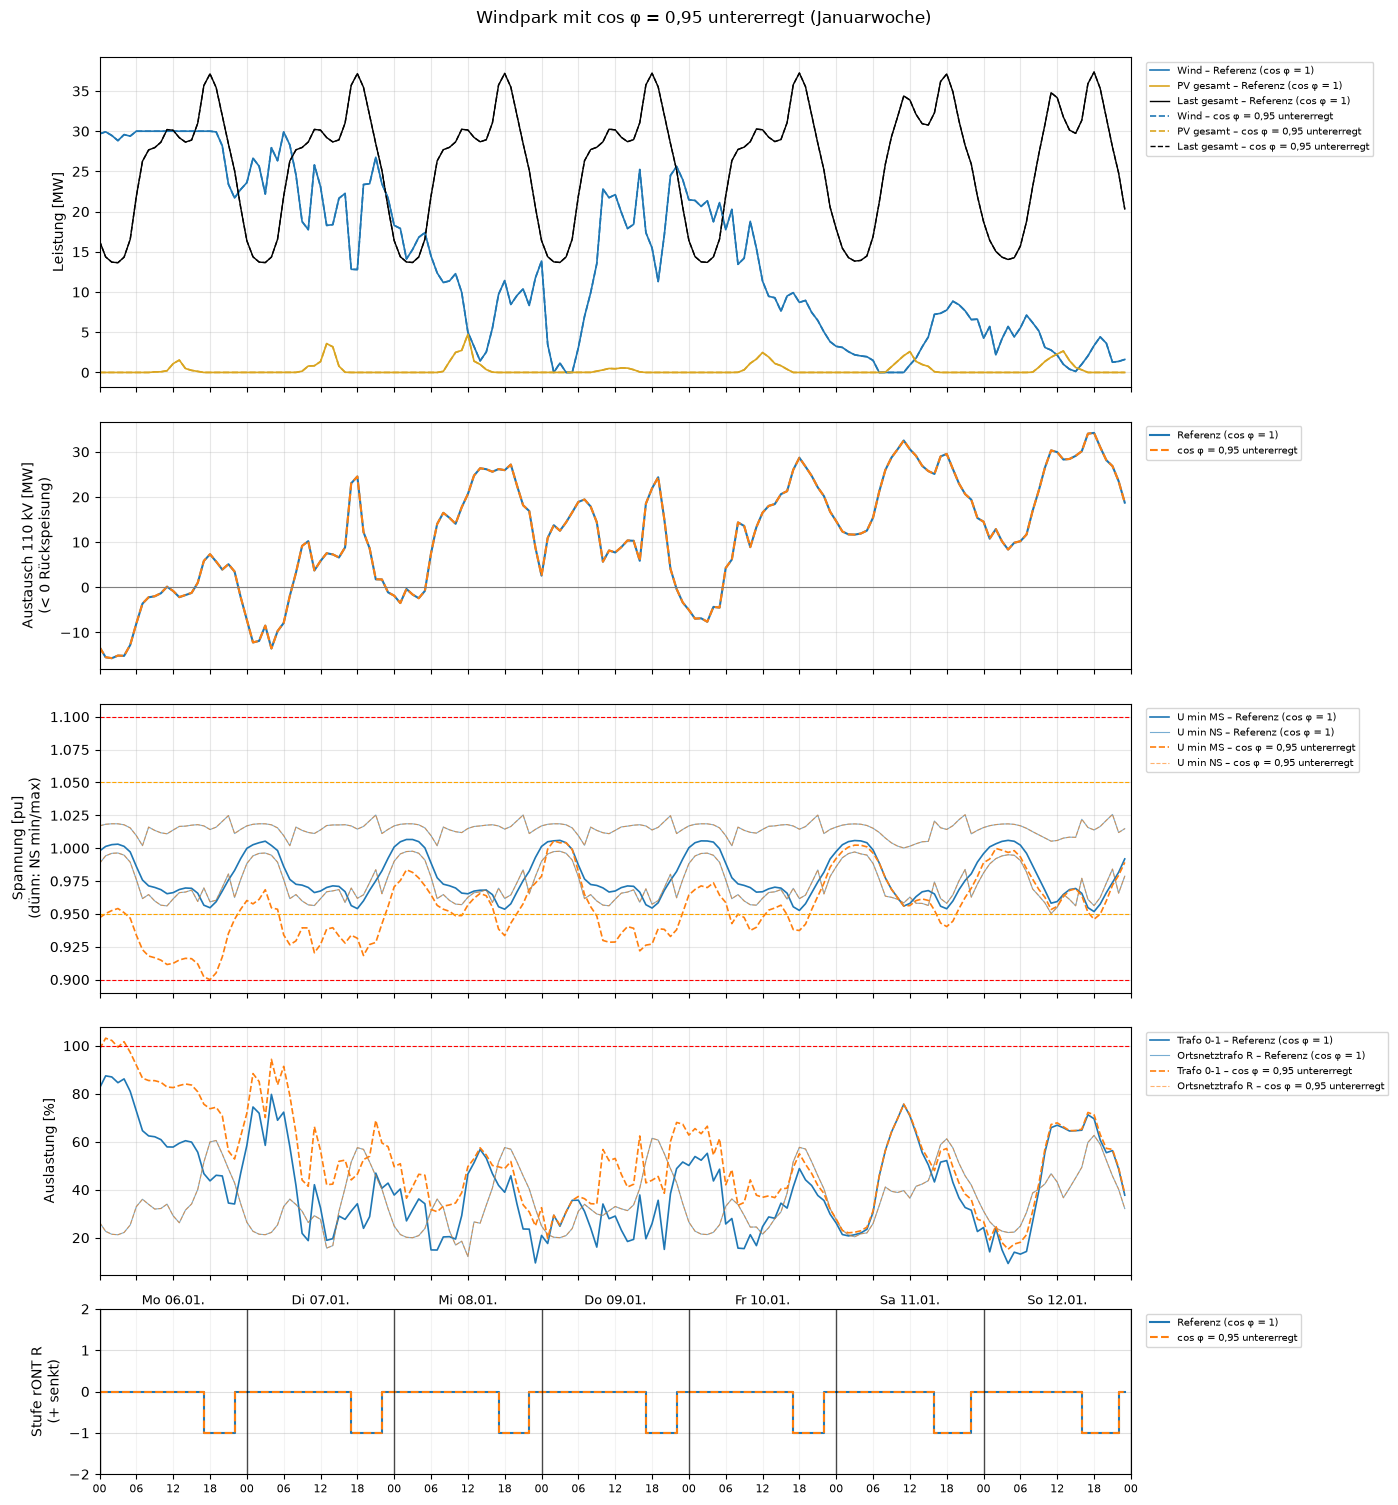

In [32]:
pr.verlauf(blind, "Windpark mit cos φ = 0,95 untererregt (Januarwoche)", monat="JANUARY")

**Befund Blindleistungsbezug:**

- Der Windpark nimmt bis **9,9 Mvar** auf, der Bezug aus dem 110-kV-Netz steigt von 11,3 auf 21,7 Mvar.
- Die Spannung in Abgang 1 sinkt: Bus 11 auf **0,900 pu** (Arbeitsgrenze), in 70 Stunden unter 0,95 pu. Trafo 0-1 wird überlastet (bis **103 %**), die Verluste steigen um 8 %.
- **Prüfungsantwort:** Untererregter Betrieb senkt die Spannung über X · Q. Das ist nur sinnvoll, wenn die Spannung zu hoch ist. In diesem Netz ist sie es nicht, deshalb schadet es. Besser: cos φ = 1 oder eine Q(U)-Kennlinie, die nur bei hoher Spannung Blindleistung aufnimmt.

## 14 Spannung im 110-kV-Netz ändert sich

**Frage:** Was passiert, wenn das überlagerte 110-kV-Netz nicht mit 1,03 pu, sondern mit 1,00 pu bzw. 1,05 pu betrieben wird?

**Annahme:** Spannung der Netzeinspeisung (`ext_grid`, im Referenznetz 1,03 pu) auf 1,00 pu im Januar (Höchstlast) und auf 1,05 pu im Juli (Rückspeisung).

In [33]:
EXT = b.net.ext_grid["name"].iloc[0]
hs = {"Januar: 1,03 pu (Referenz)": REF["JANUARY"],
      "Januar: 1,00 pu": pr.szenario("hs_100", b, monate=["JANUARY"], netz=lambda s: s.changeParameter(EXT, "vm_pu", 1.00)),
      "Juli: 1,03 pu (Referenz)": REF["JULY"],
      "Juli: 1,05 pu": pr.szenario("hs_105", b, monate=["JULY"], netz=lambda s: s.changeParameter(EXT, "vm_pu", 1.05))}
tab = pr.kennzahlen(hs)
tab

,"Januar: 1,03 pu (Referenz)","Januar: 1,00 pu","Juli: 1,03 pu (Referenz)","Juli: 1,05 pu"
Stunden gerechnet,168,168,168,168
davon nicht konvergiert,0,0,0,0
U min MS [pu],0.952 (Bus 11),0.918 (Bus 11),0.978 (Bus 11),0.999 (Bus 11)
U max MS [pu],1.023 (Bus 1),0.993 (Bus 1),1.025 (Bus 1),1.045 (Bus 1)
U min NS [pu],0.950 (R15),0.950 (I2),0.954 (C12),0.976 (C12)
U max NS [pu],1.026 (R1),1.024 (R1),1.049 (R15),1.049 (R15)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,105,0,0
"Stunden außerhalb 0,95 … 1,05 (NS)",0,0,0,0
"Stunden außerhalb 0,90 … 1,10 (alle)",0,0,0,0
Leitung max MS [%],78.491 (Line 2-3),81.377 (Line 2-3),53.339 (Line 2-3),52.175 (Line 2-3)


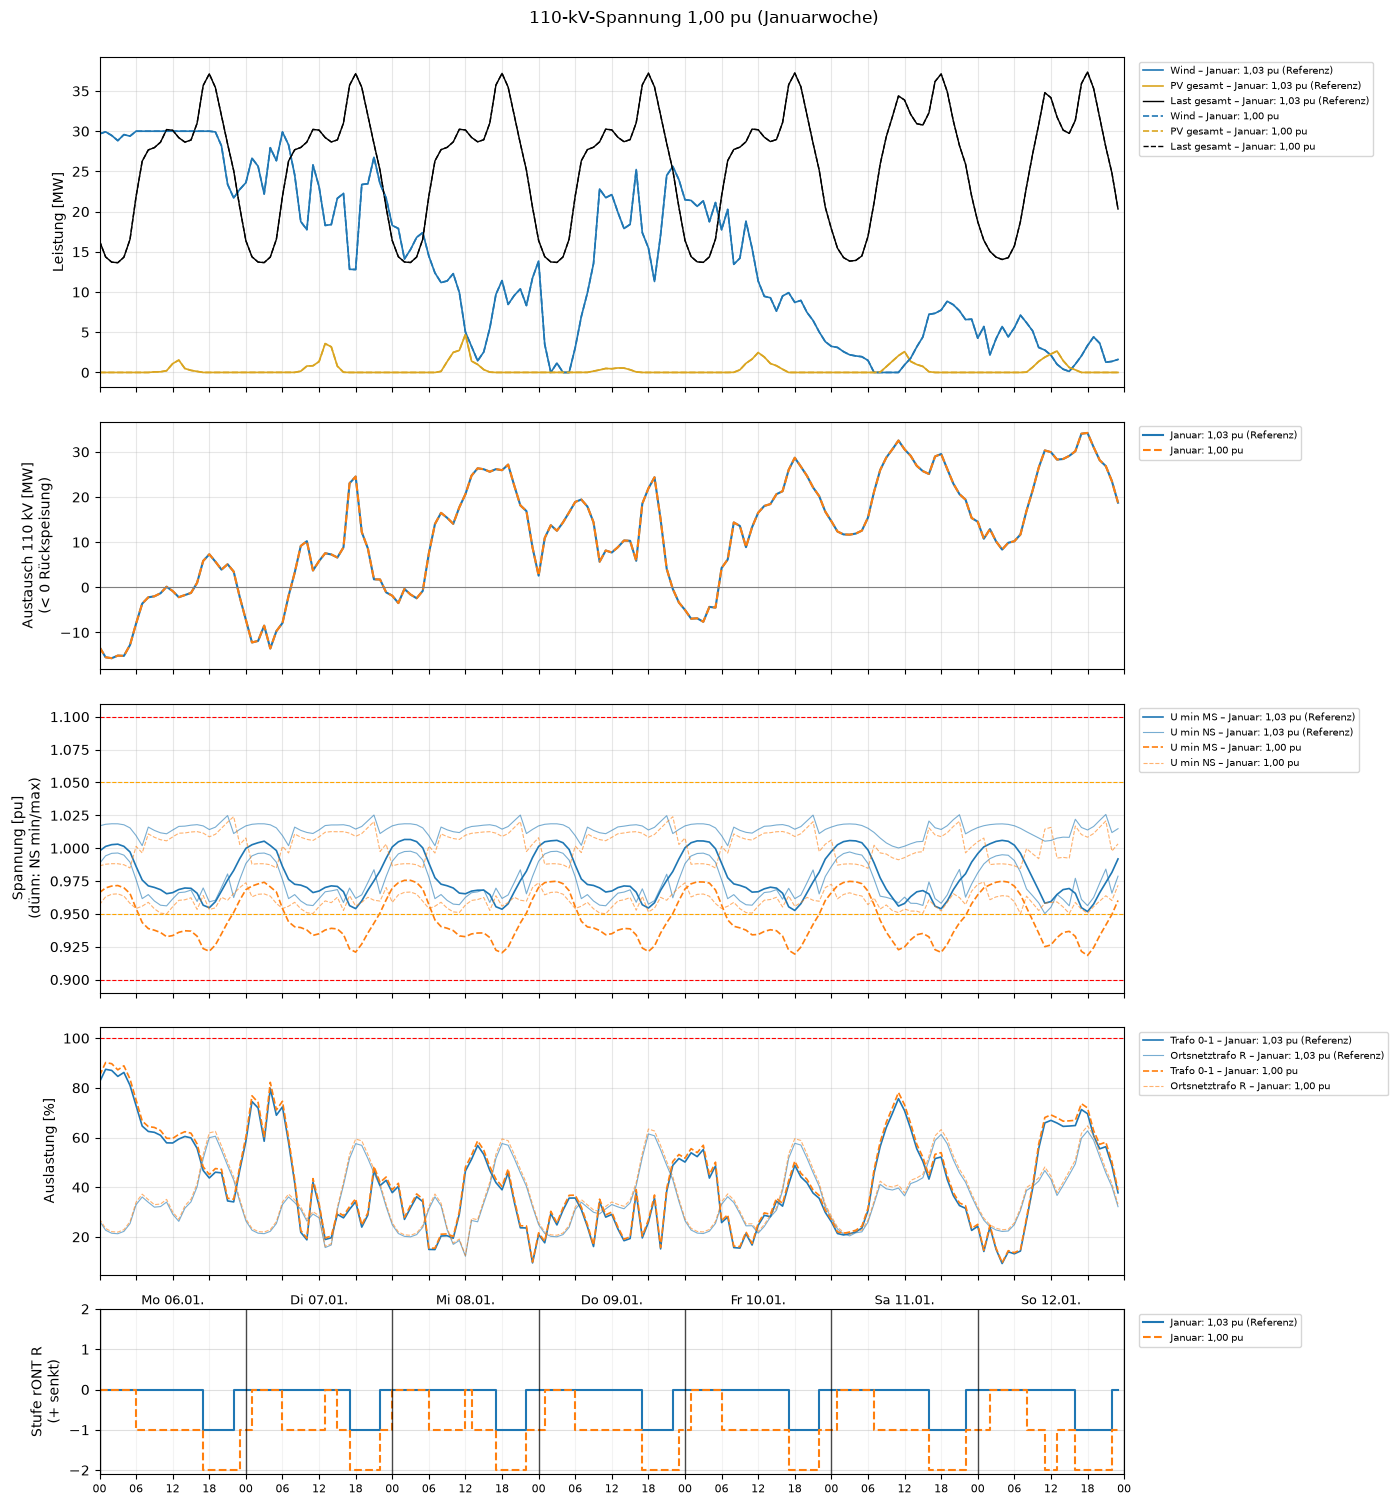

In [34]:
pr.verlauf({k: hs[k] for k in list(hs)[:2]}, "110-kV-Spannung 1,00 pu (Januarwoche)", monat="JANUARY")

**Befund 110-kV-Spannung:**

- **1,00 pu (Januar):** Das ganze MS-Netz verschiebt sich um etwa 3 Prozentpunkte nach unten: Bus 11 fällt auf **0,918 pu**, in 105 Stunden unter 0,95 pu. Das Ortsnetz bleibt im Band, weil die rONT nachregeln (65 statt 24 Stufenschritte).
- **1,05 pu (Juli):** MS-Netz bis 1,045 pu, das Ortsnetz bleibt durch den rONT bei höchstens 1,049 pu.
- **Prüfungsantwort:** Im MS-Netz gibt es keinen Regler; seine Spannung hängt direkt am überlagerten Netz und an den Trafos 110/20 kV (deren Stufenschalter hier fest sind). Nur das Ortsnetz wird durch die rONT entkoppelt.

## 15 Zusätzliche Einspeisung an Bus 8

**Frage:** Ab welcher zusätzlichen Einspeisung an Bus 8 wird Line 3-8 im Netz am Ende von Teil 4 zum Engpass (vgl. Teil 6, dort im Referenznetz ohne Erzeuger)?

**Annahme:** Juliwoche, zusätzlicher Erzeuger mit konstanter Leistung (Profil FEST) an Bus 8: 2, 4, 6 und 8 MW.

In [35]:
def bus8(p):
    return lambda s: s.createElement(Generator("Einspeisung Bus 8", bus="Bus 8", profile=Profile.FEST, p_mw=p))

b8 = {"Referenz": REF["JULY"]} | {f"{p} MW an Bus 8": pr.szenario(f"bus8_{p}", b, monate=["JULY"], netz=bus8(p)) for p in (2, 4, 6, 8)}
tab = pr.kennzahlen(b8)
display(tab)
pd.DataFrame({k: {l: s.results.line_loading[l].max() for l in ("Line 3-8", "Line 2-3", "Line 1-2", "Line 8-9")}
              for k, s in b8.items()}).round(1)

,Referenz,2 MW an Bus 8,4 MW an Bus 8,6 MW an Bus 8,8 MW an Bus 8
Stunden gerechnet,168,168,168,168,168
davon nicht konvergiert,0,0,0,0,0
U min MS [pu],0.978 (Bus 11),0.999 (Bus 6),1.010 (Bus 14),1.010 (Bus 14),1.010 (Bus 14)
U max MS [pu],1.025 (Bus 1),1.033 (Bus 8),1.052 (Bus 8),1.069 (Bus 8),1.085 (Bus 8)
U min NS [pu],0.954 (C12),0.954 (C12),0.954 (C12),0.954 (C12),0.954 (C12)
U max NS [pu],1.049 (R15),1.049 (R15),1.049 (R15),1.049 (R15),1.049 (R15)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,0,29,89,168
"Stunden außerhalb 0,95 … 1,05 (NS)",0,0,0,0,0
"Stunden außerhalb 0,90 … 1,10 (alle)",0,0,0,0,0
Leitung max MS [%],53.339 (Line 2-3),28.854 (Line 3-8),66.166 (Line 3-8),102.395 (Line 3-8),137.733 (Line 3-8)


,Referenz,2 MW an Bus 8,4 MW an Bus 8,6 MW an Bus 8,8 MW an Bus 8
Line 3-8,25.2,28.9,66.2,102.4,137.7
Line 2-3,53.3,18.1,55.4,91.7,127.2
Line 1-2,53.0,17.8,55.3,91.6,127.1
Line 8-9,18.8,18.3,17.9,17.6,17.3


**Befund Einspeisung an Bus 8:**

- Bei 2 MW sinkt die Auslastung von Line 2-3 und 1-2 zuerst (53 → 18 %), weil die Einspeisung die Last in Abgang 1 deckt. Danach kehrt sich der Fluss um und die Auslastung steigt wieder.
- Line 3-8 erreicht ihre Grenze zwischen 4 und 6 MW (102 % bei 6 MW), bei 8 MW ist sie in allen Stunden überlastet (138 %). Line 2-3 und 1-2 folgen dicht dahinter (bei 6 MW 92 %, bei 8 MW 127 %).
- Die Spannung an Bus 8 steigt auf 1,05 pu (4 MW) bis 1,085 pu (8 MW), also über das Planungsband.
- Im Vergleich zu Teil 6 (6,49 MW bei 60 % Last ohne Erzeuger) liegt die Grenze hier etwas niedriger (knapp 6 MW), weil die Last in Abgang 1 im Juli nachts unter 60 % liegt und weniger von der Einspeisung vor Ort verbraucht wird.
- **Prüfungsantwort:** Eine Einspeisung mitten im Abgang belastet zuerst die Leitung, über die sie abfließt, und hebt dort die Spannung an.

## 16 Heimspeicher

**Frage:** Wie viel tragen die Heimspeicher zur Entlastung des Wohngebiets bei? Was würde ein doppelt so großer Speicher bringen?

**Annahme:** Juliwoche. **a)** alle Heimspeicher außer Betrieb, **b)** Kapazität und Leistung aller Heimspeicher verdoppelt. Die Speicher fahren weiter den Eigenverbrauchsfahrplan (laden, sobald PV-Überschuss da ist).

In [36]:
def ohne_speicher(s):
    s.net.storage["in_service"] = False

def doppelt(s):
    s.net.storage["max_e_mwh"] *= 2
    s.net.storage["max_p_mw"] *= 2
    s.net.storage["min_p_mw"] *= 2

speicher = {"a) ohne Speicher": pr.szenario("ohne_speicher", b, monate=["JULY"], netz=ohne_speicher),
            "Referenz (314 kWh)": REF["JULY"],
            "b) doppelte Speicher (628 kWh)": pr.szenario("speicher_doppelt", b, monate=["JULY"], netz=doppelt)}
tab = pr.kennzahlen(speicher)
display(tab)
pd.DataFrame({k: {"Rückspeisung Wohngebiet [MWh]": -s.results.trafo_p_mw[pr.ONT["R"]].clip(upper=0).sum(),
                  "Bezug Wohngebiet [MWh]": s.results.trafo_p_mw[pr.ONT["R"]].clip(lower=0).sum(),
                  "Speicher geladen [MWh]": s.results.storage_p_mw.clip(lower=0).sum().sum() if s.results.storage_p_mw.shape[1] else 0.0}
              for k, s in speicher.items()}).round(2)

,a) ohne Speicher,Referenz (314 kWh),b) doppelte Speicher (628 kWh)
Stunden gerechnet,168,168,168
davon nicht konvergiert,0,0,0
U min MS [pu],0.978 (Bus 11),0.978 (Bus 11),0.978 (Bus 11)
U max MS [pu],1.025 (Bus 1),1.025 (Bus 1),1.025 (Bus 1)
U min NS [pu],0.954 (C12),0.954 (C12),0.954 (C12)
U max NS [pu],1.049 (R15),1.049 (R15),1.049 (R15)
"Stunden außerhalb 0,95 … 1,05 (MS)",0,0,0
"Stunden außerhalb 0,95 … 1,05 (NS)",0,0,0
"Stunden außerhalb 0,90 … 1,10 (alle)",0,0,0
Leitung max MS [%],53.339 (Line 2-3),53.339 (Line 2-3),53.339 (Line 2-3)


,a) ohne Speicher,Referenz (314 kWh),b) doppelte Speicher (628 kWh)
Rückspeisung Wohngebiet [MWh],8.28,7.94,7.64
Bezug Wohngebiet [MWh],14.65,14.65,14.67
Speicher geladen [MWh],0.00,0.93,1.26


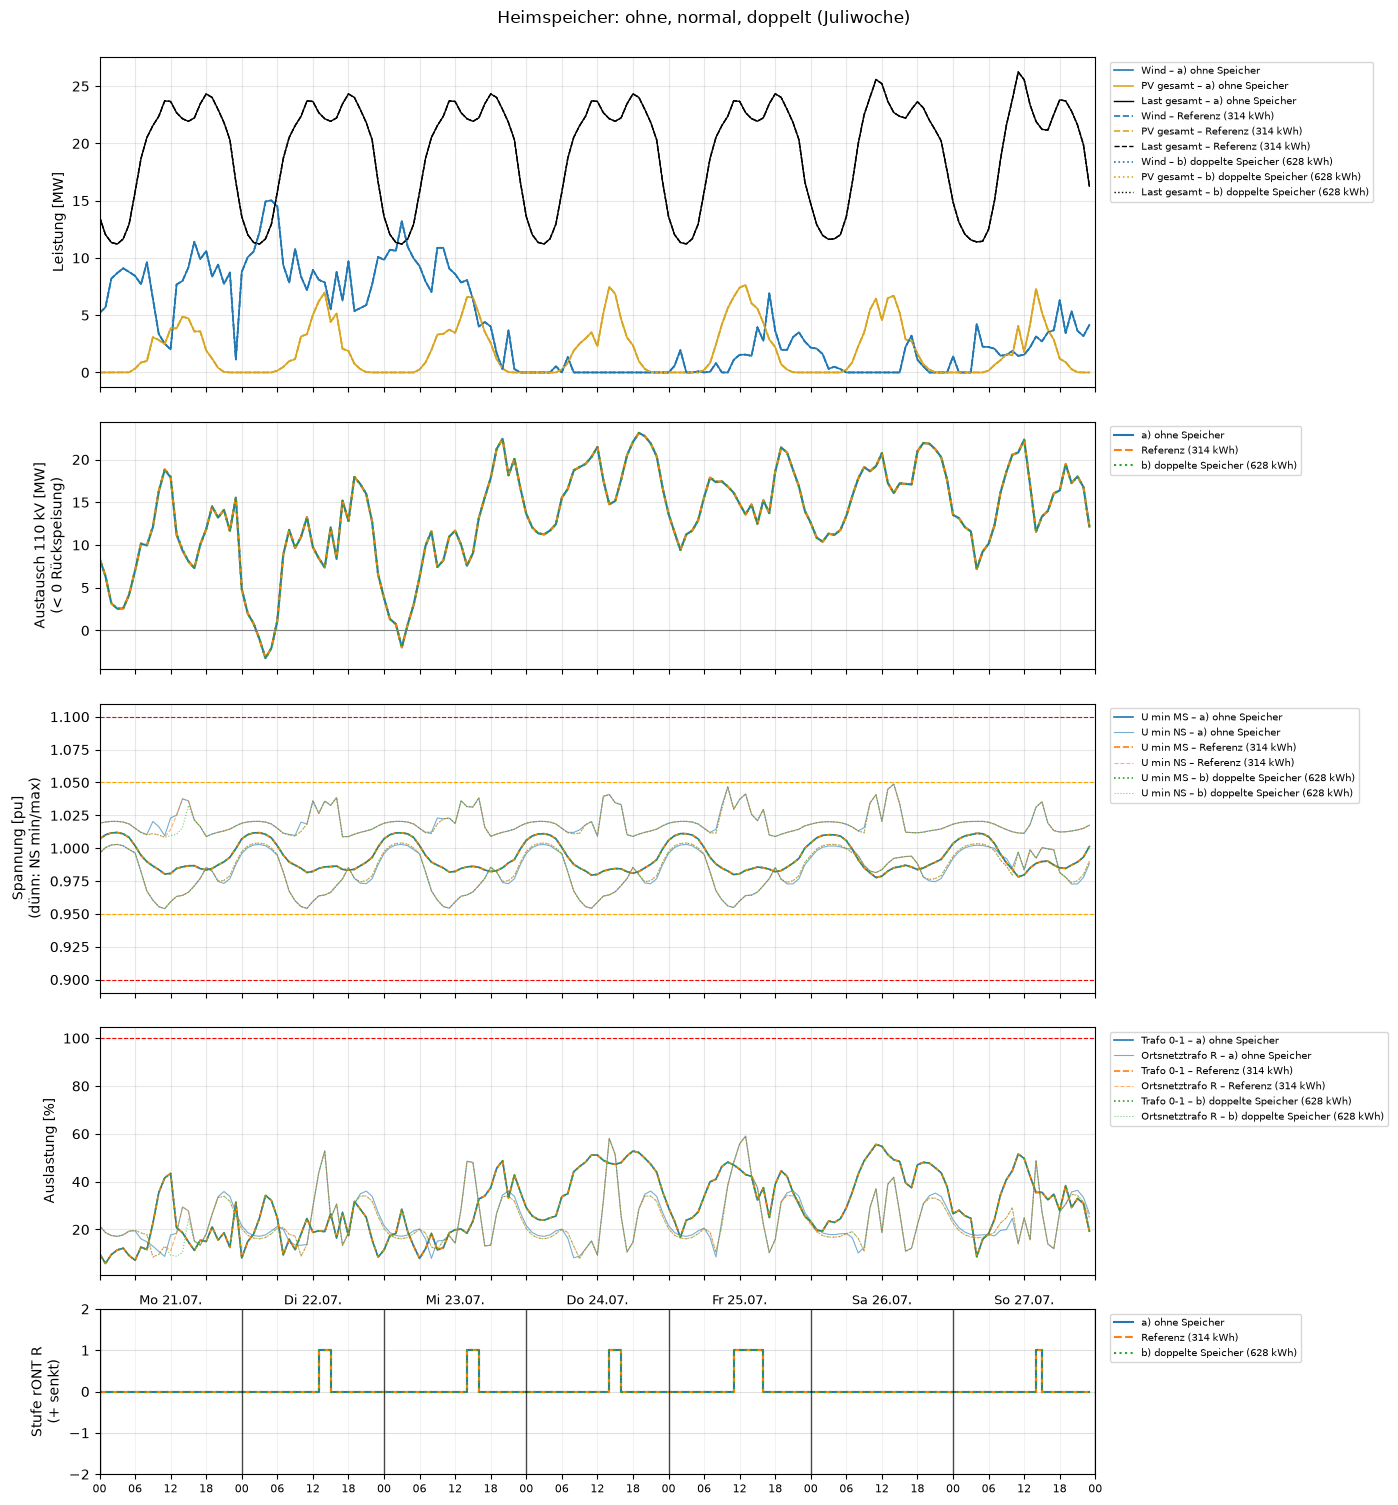

In [37]:
pr.verlauf(speicher, "Heimspeicher: ohne, normal, doppelt (Juliwoche)", monat="JULY")

**Befund Heimspeicher:**

- Ohne Speicher speist das Wohngebiet 8,3 MWh zurück, mit Speicher 7,9, mit doppelter Kapazität 7,6 MWh. Die **größte Rückspeisung bleibt in allen Fällen 360 kW**, auch die Spannung (1,049 pu) und die Trafoauslastung ändern sich nicht.
- Grund: Die Speicher laden morgens mit dem ersten Überschuss und sind vor der Mittagsspitze voll. Ein größerer Speicher ist nur etwas später voll.
- **Prüfungsantwort:** Heimspeicher mit Eigenverbrauchsregelung erhöhen den Eigenverbrauch, entlasten das Netz bei der Spitze aber nicht. Netzdienlich wären sie nur, wenn sie erst zur Mittagsspitze laden (mit PV-Prognose) oder eine feste Einspeisegrenze einhalten (Ausblick Teil 9).

## 17 Übersicht

Alle Varianten nebeneinander (jeweils die typische Woche des Szenarios). Grenzwertverletzungen: Spannung außerhalb 0,90 … 1,10 pu oder Auslastung über 100 %.

In [38]:
alle = {}
for gruppe in (wolken, haushalte, flaute, starkwind, sturm, sonntag_sims, s1, leitung, trafo, ront, blind, hs, b8, speicher):
    for k, s in gruppe.items():
        if not k.lower().startswith(("referenz", "100 %")) and "rONT" not in k and "Referenz" not in k:
            alle[f"{s.name.replace(pr.PREFIX, '')}"] = s
ueb = pr.kennzahlen(alle).T[["davon nicht konvergiert", "U min MS [pu]", "U max MS [pu]", "U min NS [pu]", "U max NS [pu]",
                             "Stunden außerhalb 0,90 … 1,10 (alle)", "Leitung max MS [%]", "Trafo 0-1 max [%]",
                             "Ortsnetztrafo R max [%]", "Stunden mit Überlastung (> 100 %)", "max. Rückspeisung 110 kV [MW]"]]
ueb

,davon nicht konvergiert,U min MS [pu],U max MS [pu],U min NS [pu],U max NS [pu],"Stunden außerhalb 0,90 … 1,10 (alle)",Leitung max MS [%],Trafo 0-1 max [%],Ortsnetztrafo R max [%],Stunden mit Überlastung (> 100 %),max. Rückspeisung 110 kV [MW]
wolken_mittag,0,0.978 (Bus 11),1.025 (Bus 1),0.954 (C12),1.049 (R15),0,53.339 (Line 2-3),55.6,58.1,0,3.24
wolkenzug,0,0.978 (Bus 11),1.025 (Bus 1),0.953 (C12),1.050 (R15),0,53.339 (Line 2-3),55.6,58.1,0,3.24
last_plus30,0,0.952 (Bus 11),1.023 (Bus 1),0.952 (R15),1.044 (R1),0,78.491 (Line 2-3),87.5,82.4,0,15.66
last_abend60,0,0.952 (Bus 11),1.023 (Bus 1),0.934 (R15),1.039 (R1),0,78.491 (Line 2-3),87.5,102.9,9,15.70
last_plus60,0,0.952 (Bus 11),1.023 (Bus 1),0.932 (R15),1.047 (R1),0,78.491 (Line 2-3),87.5,105.1,10,15.62
flaute_60,0,0.951 (Bus 11),1.023 (Bus 1),0.952 (R15),1.025 (R1),0,78.547 (Line 2-3),75.7,65.1,0,3.93
flaute_30,0,0.950 (Bus 11),1.023 (Bus 1),0.952 (R15),1.025 (R1),0,78.592 (Line 2-3),78.7,66.8,0,0.00
flaute_0,0,0.949 (Bus 11),1.022 (Bus 12),0.952 (R15),1.025 (R1),0,78.638 (Line 2-3),82.7,66.8,0,0.00
starkwind_30,0,0.977 (Bus 11),1.024 (Bus 12),0.951 (C12),1.048 (R15),0,53.921 (Line 2-3),94.3,70.6,0,18.76
starkwind_45,0,0.977 (Bus 11),1.024 (Bus 12),0.951 (C12),1.048 (R15),0,53.921 (Line 2-3),154.6,70.6,42,33.70


**Zusammenfassung für die Prüfung:**

| Szenario | Was wird kritisch? |
|---|---|
| Wolken | kurze Leistungssprünge im Ortsnetz, rONT-Schalthäufigkeit; keine Grenzverletzung |
| mehr Verbrauch | zuerst Ortsnetztrafo und erstes Kabel (über 100 % ab ca. +60 %), dann die Spannung am Strangende |
| Dunkelflaute | nichts im Verteilnetz (Auslegung auf Höchstlast); mehr Bezug aus dem 110-kV-Netz |
| Starkwind nachts | Trafo 0-1 thermisch (94 %, bei 45 MW 155 %) |
| Sturmabschaltung | im Verteilnetz unkritisch, 30 MW Sprung für das überlagerte Netz |
| Sonne + geringe Last | Spannung am Strangende; in der Variante Zukunft Trafo und Kabel weit überlastet |
| S1 zu bei Wind | Line 1-2 an der Grenze, +63 % Verluste |
| Ausfall Line 2-3 | beherrschbar über S1, Spannung bis 0,926 pu |
| Ausfall Trafo 0-1 | nicht beherrschbar (Überspannung bzw. Spannungskollaps) |
| rONT fest | Wohngebiet im Winter zu tief, im Sommer zu hoch |
| cos φ 0,95 untererregt | Abgang 1 bis 0,90 pu, Trafo 0-1 überlastet |
| 110 kV 1,00 pu | MS-Netz bis 0,918 pu; Ortsnetz durch rONT geschützt |
| Einspeisung Bus 8 | Line 3-8 ab gut 4 MW |
| Speicher | kein Einfluss auf die Rückspeisespitze |

Mit dem Werkzeug aus Abschnitt 1 lassen sich weitere Fragen direkt rechnen: neue Variante mit `pr.szenario("name", b, monate=[...], aenderungen=[...], netz=...)`, danach `pr.kennzahlen({...})` und `pr.verlauf({...}, monat=...)`.